# Recommender Systems - Mini Challenge FS26

In this minichallenge we will explore a MovieLens dataset and implement several recommender systems and evaluation methods. Subsequently we will optimize these methods and compare the results. 

**Submission deadline:** Sunday of SW11 at 18:00 

## Guidelines for Implementation and Submission
- Code must be written in Python. The versions of all used packages must be given for reproducability.
- You may respond in English or German.
- We develop numerous algorithms ourselves. Unless explicitly stated otherwise, only the following libraries may be used in Python: numpy, matplotlib, seaborn, pandas. 
- Follow good coding practices and write modular, reusable code.
- The submitted solution must contain all codes and the results. No code may be outsourced.
- All pathes must be relative and just downloading your repo must be executable without modifications.
- Only fully running code is graded. The notebook must run sequential from start to end.
- During development, if computation time is too long for productive prototyping and debugging work, it is recommended to reduce the dataset to a fraction of its original. However, final results must be calculated on the full dataset. 
- All plots must be fully labeled (title, axes, labels, colorbar, etc.) so that the plot can be easily understood.
- Each plot must be accompanied by a brief discussion, which explains the plot and captures the key insights that become visible.
- Only fully labeled plots with an accompanying discussion will be assessed.
- The last commit in your fork of the repo before the submission deadline counts as the submission.
- Points will be deducted if you write inconsise (Denial of service will be punished) or if I read text not written for me but for the user of ChatGPT oir similar. 
- If you would like to submit and have the mini-challenge assessed, please send a short email to the subject expert (moritz.kirschmann@fhnw.ch) within 2 days after submission.
- Please do not delete, duplicate, or move the existing cells. This leads to problems during the correction. However, you may add as many additional cells as you like.

## Exercises

### Exercise 1 - A deep exploration of the dataset (17 points)
We will work with a subset of the MovieLens dataset. This subset is located under ``data/ml-latest-small``. Read the ``README.txt``carefully. 
Open the files. 

a) Describe the available data.

b) Find and fix bad data (e.g. duplicates, missing values, etc.).

Generate lists of

c) - Top 20 movies by average rating

d) - Top 20 movies by number of views

e) What is the range of the ratings? 

f) Which genre has be rated how many times?

g) How sparse is the User Rating Matrix?

Plot the following:

h) How many users have rated how many movies

i) Which rating is given how often over time with a time resolution of month 

j) Which rating is given how often per genre

k) The rating distributions of 10 random movies

l) The rating distributions of 3 movies that you have watched

m) How many users give which average rating

n) How often a movie was rated as a function of average rating

o) A heatmap of the User Item Matrix

p) A heatmap of the User Item Matrix for the 100 most rated movies for the 50 users with most ratings


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import cython
import surprise
from surprise import SVD

**a) Describe the available data**

As the provided summary states the dataset describes 5-star rating and free-text tagging activity from MovieLens, a movie recommendation service. It contains 100836 ratings and 3683 tag applications across 9742 movies made by 610 users between March 29, 1996 and September 24, 2018

In [2]:
movies = pd.read_csv("./Data/ml-latest-small/movies.csv")
ratings = pd.read_csv("./Data/ml-latest-small/ratings.csv")
tags = pd.read_csv("./Data/ml-latest-small/tags.csv")

movies.info()
ratings.info()
tags.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   userId     3683 non-null   int64
 1   movieId    3683 non-null   int64
 2   tag        3683 non-null   str

The dataset consists of three main components: movies, ratings, and tags.

The `movies` dataset contains information on 9,742 movies each with unique `movieId`, including their titles and associated genres. Genres are provided as categorical descriptors and may include multiple labels per movie.

The `ratings` dataset contains 100,836 user ratings. Each entry represents a rating given by a specific user (`userId`) to a specific movie (`movieId`). Users can rate multiple movies, resulting in multiple entries per user. Ratings are given on a 5-star scale with half-star increments, ranging from 0.5 to 5.0. Additionally, each rating includes a timestamp indicating when the rating was submitted, measured in seconds since January 1, 1970 (UTC).

The `tags` dataset contains user-generated annotations for movies. Each entry links a user (`userId`) to a movie (`movieId`) and includes a tag, typically a short word or phrase describing some aspect of the movie. Similar to the ratings data, a timestamp is provided to indicate when the tag was created.

Overall, the dataset combines explicit feedback (ratings) with descriptive metadata (genres and tags).

**b) Find and fix bad data (e.g. duplicates, missing values, etc.).**

Beyond duplicates and missing values, I will also check for data consistency, validity, and structural issues.


In [3]:
# 1) Ensuring correct data types
ratings['userId'] = ratings['userId'].astype(int)
ratings['movieId'] = ratings['movieId'].astype(int)
movies['movieId'] = movies['movieId'].astype(int)
ratings['rating'] = ratings['rating'].astype(float)
tags['userId'] = tags['userId'].astype(int)
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')
tags['timestamp'] = pd.to_datetime(tags['timestamp'], unit='s')

# 2) No duplicates
movies = movies.drop_duplicates(subset=['movieId'])
ratings = ratings.drop_duplicates(subset=['userId', 'movieId'])

# 3) No NaN
def nan_check(data):
    total_nans = data.isna().sum().sum()
    per_column = data.isna().sum()
    any_nans = data.isna().any().any()

    print("Total NaNs:", total_nans)
    print("\nNaNs per column:")
    print(per_column)
    print("\nAny NaNs present:", any_nans)

    return total_nans, per_column, any_nans

for name, data in [("movies", movies), ("ratings", ratings), ("tags", tags)]:
    print(f"\n--- {name} ---")
    nan_check(data)

# 4) No invalid ratings
invalid_ratings = ratings[(~ratings['rating'].between(0.5, 5.0)) | (ratings['rating'] % 0.5 != 0)]
print("Number of invalid ratings:", len(invalid_ratings))

# 5)  movieIds in ratings must be in movies
if ratings['movieId'].isin(movies['movieId']).all():
    print("All movieIds in ratings exist in movies")
else:
    print("There are ratings for movies not present in the movies dataset")



--- movies ---
Total NaNs: 0

NaNs per column:
movieId    0
title      0
genres     0
dtype: int64

Any NaNs present: False

--- ratings ---
Total NaNs: 0

NaNs per column:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Any NaNs present: False

--- tags ---
Total NaNs: 0

NaNs per column:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Any NaNs present: False
Number of invalid ratings: 0
All movieIds in ratings exist in movies


I checked for common data quality issues and cleaned where necessary. I convertent columns to appropriate data types to ensure consistency, and made sure the timestamps are in a readable datetime format. Duplicate entries were then removed from the `movies` and `ratings` datasets based on their identifying columns.

Then I checked all three datasets (`movies`, `ratings`, and `tags`) for missing values with a reusable function. No missing values were found in any column. The ratings were also validated to ensure that they lie within the allowed range from 0.5 to 5.0 and follow the required half-star increments. No invalid ratings were detected. Finally, referential integrity was verified by confirming that all `movieId` values appearing in the `ratings` dataset also exist in the `movies` dataset.

Overall, the dataset seems clean, consistent, and suitable for building recommendation systems as expected from GroupLens.

**c) - Top 20 movies by average rating**

In [4]:
# A dataframe with title and average ratings
movieId_avrating = ratings.groupby('movieId')['rating'].mean().reset_index()
movies_with_ratings = movies.merge(movieId_avrating, on='movieId', how='inner')
print(movies_with_ratings.sort_values(by='rating', ascending=False).head(20)) # print top 20

      movieId                                              title  \
7638    88448              Paper Birds (Pájaros de papel) (2010)   
8089   100556                         Act of Killing, The (2012)   
9065   143031                                    Jump In! (2007)   
9076   143511                                       Human (2015)   
9078   143559                                L.A. Slasher (2015)   
4245     6201                                   Lady Jane (1986)   
8136   102217                     Bill Hicks: Revelations (1993)   
8130   102084                       Justice League: Doom (2012)    
4240     6192          Open Hearts (Elsker dig for evigt) (2002)   
9104   145994                             Formula of Love (1984)   
8097   100906                                Maniac Cop 2 (1990)   
9111   146662             Dragons: Gift of the Night Fury (2011)   
8056    99636                            English Vinglish (2012)   
5771    31522  Marriage of Maria Braun, The (Ehe

I made a list (not a literal Python list) of the top 20 movies based on their average rating. It was generated by grouping the ratings by movieId, computing the mean rating, and sorting the results in descending order. It is clear that the top spots are dominated by movies with perfect scores, which likely have only very few reviews. In a recommender system, a more robust approach would be to introduce a damping or weighting mechanism to penalise entries with fewer reviews. However, I assume this is not required for this task and will consider it later when building the actual recommendation system.

**d) - Top 20 movies by number of views**

In [5]:
# A dataframe with title and amount of ratings
rating_amount = ratings.groupby('movieId')['rating'].count().reset_index(name='num_ratings')
movies_with_rating_amount = movies.merge(rating_amount, on='movieId', how='inner')
print(movies_with_rating_amount.sort_values(by='num_ratings', ascending=False).head(20)) # print top 20

      movieId                                              title  \
314       356                                Forrest Gump (1994)   
277       318                   Shawshank Redemption, The (1994)   
257       296                                Pulp Fiction (1994)   
510       593                   Silence of the Lambs, The (1991)   
1938     2571                                 Matrix, The (1999)   
224       260          Star Wars: Episode IV - A New Hope (1977)   
418       480                               Jurassic Park (1993)   
97        110                                  Braveheart (1995)   
507       589                  Terminator 2: Judgment Day (1991)   
461       527                            Schindler's List (1993)   
2224     2959                                  Fight Club (1999)   
0           1                                   Toy Story (1995)   
897      1196  Star Wars: Episode V - The Empire Strikes Back...   
46         50                         Usual Susp

I presumed that “top 20 by views” refers to the top 20 movies by the number of reviews in the ratings dataset. I used the same technique as for the top 20 list by average rating. It becomes clear that the most viewed movies are not the same as the top 20 highest-rated movies. This is likely because a larger number of reviewers introduces more variation in the scores due to users’ individual preferences. This indicates that the number of ratings should be taken into account when designing a robust recommender system.

**e) What is the range of the ratings?**

In [6]:
print("Min rating:", ratings['rating'].min()) # As expected the worst rating is the lowest possible rating of 0.5
print("Max rating:", ratings['rating'].max()) # As expected the best rating is the highest possible rating of 5.0

Min rating: 0.5
Max rating: 5.0


**f) Which genre has be rated how many times?**

In [7]:
# merge ratings with movies to get genres per rating
ratings_with_genres = ratings.merge(movies[['movieId', 'genres']], on='movieId')

# split genres and explode into separate rows
genres_exploded = ratings_with_genres['genres'].str.split('|').explode()

# How often each genre was rated
genre_counts = genres_exploded.value_counts()

print(genre_counts) # Shows how many times has each genre been rated

genres
Drama                 41928
Comedy                39053
Action                30635
Thriller              26452
Adventure             24161
Romance               18124
Sci-Fi                17243
Crime                 16681
Fantasy               11834
Children               9208
Mystery                7674
Horror                 7291
Animation              6988
War                    4859
IMAX                   4145
Musical                4138
Western                1930
Documentary            1219
Film-Noir               870
(no genres listed)       47
Name: count, dtype: int64


**g) How sparse is the User Rating Matrix?**

Sparsity describes how many entries in the user–item matrix are missing (i.e., movies that users have not rated). It can be calculated as:

$$ sprasity = 1 - \frac{number~of~ratings}{number~of~users~\times~number~of~movies}$$

In [8]:
n_users = ratings['userId'].nunique()
n_movies = ratings['movieId'].nunique()
n_ratings = len(ratings)

sparsity = 1 - (n_ratings / (n_users * n_movies))

print("Number of users:", n_users)
print("Number of movies:", n_movies)
print("Number of ratings:", n_ratings)
print("Sparsity:", sparsity)

Number of users: 610
Number of movies: 9724
Number of ratings: 100836
Sparsity: 0.9830003169443864


I calculated the sparsity of the user–rating matrix and found it to be approximately 0.983. This means that about 98.3% of all possible user–movie interactions are missing, and only a very small fraction of ratings is actually observed. This confirms that the dataset is highly sparse, which is typical for recommender systems and makes the task of generating accurate recommendations more challenging.

**h) How many users have rated how many movies**

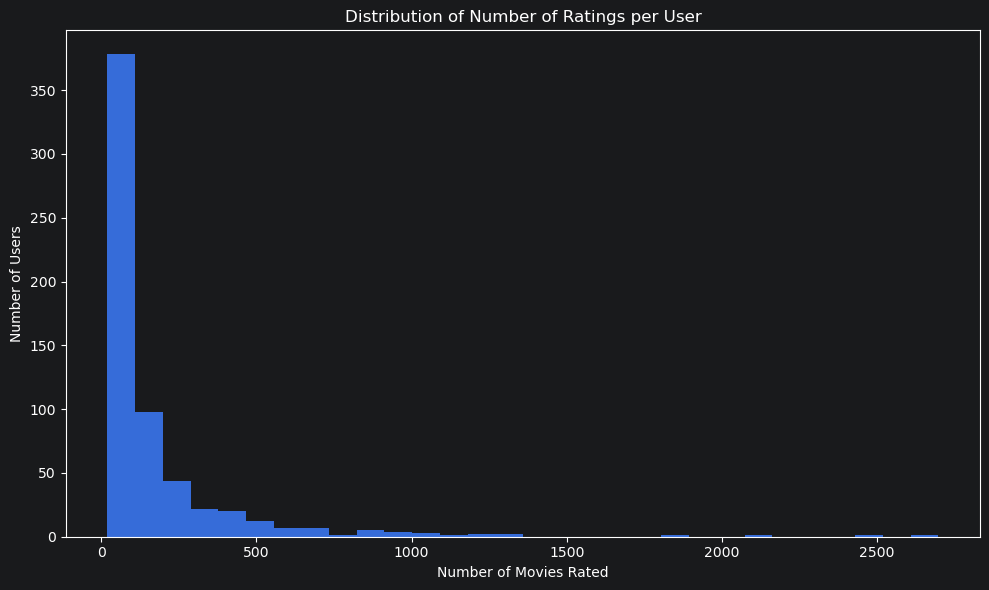

In [9]:
# How many movies each user rated
ratings_per_user = ratings.groupby('userId')['movieId'].count()

# plot distribution
plt.figure(figsize=(10, 6))
plt.hist(ratings_per_user, bins=30)

plt.title("Distribution of Number of Ratings per User")
plt.xlabel("Number of Movies Rated")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

As I already intreperted by the calculated sparsity, the left-skewed histogram shows that most users have rated only a small number of movies, while a few users have rated a much larger number. This highlights the uneven distribution of user activity in the dataset.

**i) Which rating is given how often over time with a time resolution of month**

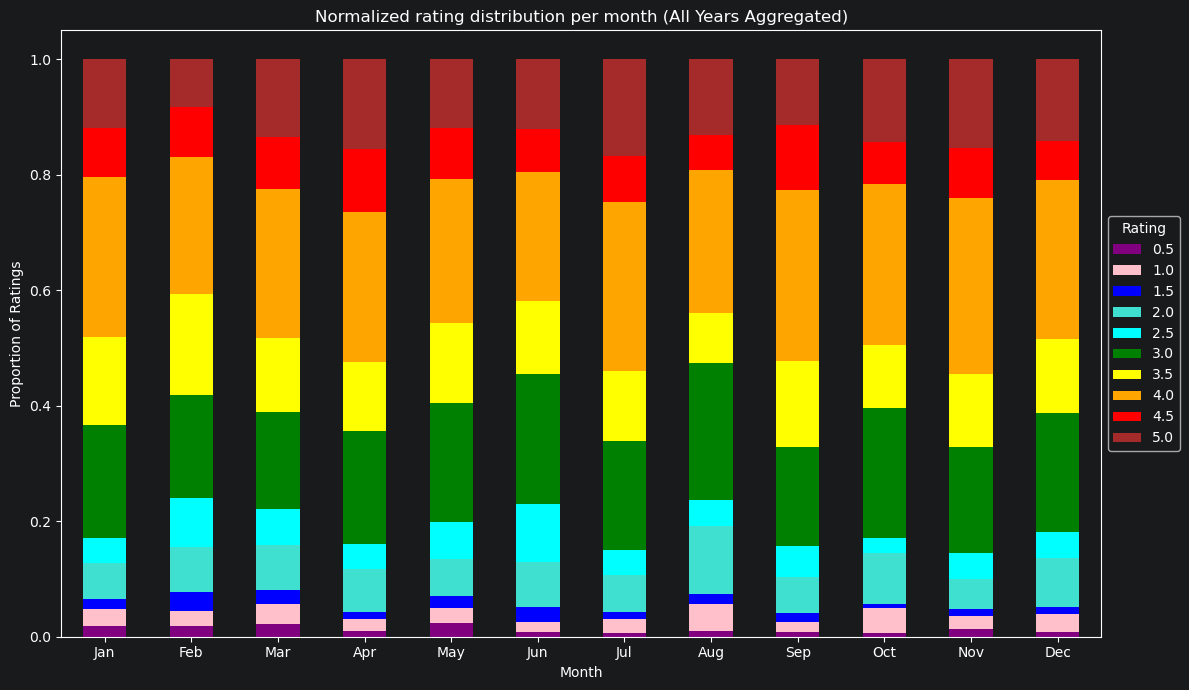

In [10]:
# timestamp -> datetime
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')

# extract month
ratings['month'] = ratings['timestamp'].dt.month

# ratings per month and rating
month_rating = (
    ratings
    .groupby(['month', 'rating'])
    .size()
    .unstack(fill_value=0)
)

# normalize per month
month_rating_norm = month_rating.div(month_rating.sum(axis=1), axis=0)

# column sort
month_rating_norm = month_rating_norm.sort_index(axis=1)

# rating colors more or less based on color spectrum
rating_colors = {
    0.5: 'purple',
    1.0: 'pink',
    1.5: 'blue',
    2.0: 'turquoise',
    2.5: 'cyan',
    3.0: 'green',
    3.5: 'yellow',
    4.0: 'orange',
    4.5: 'red',
    5.0: 'brown'
}

# fixed colors
colors = [rating_colors[r] for r in month_rating_norm.columns]

# plot
month_rating_norm.plot(kind='bar', stacked=True, figsize=(12, 7), color=colors)

plt.title("Normalized rating distribution per month (All Years Aggregated)")
plt.xlabel("Month")
plt.ylabel("Proportion of Ratings")

plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    rotation=0)

plt.legend(title="Rating", loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

My key takeaway from this plot is that higher ratings (around 4.0 – 5.0) make the majority of ratings, while lower ratings tend to get rarer the lower they are. The time of the year does not really seem to have a big impact on the user's rating score. This indicates a positive bias in the dataset, where users are more likely to rate movies they enjoyed.

**j) Which rating is given how often per genre**

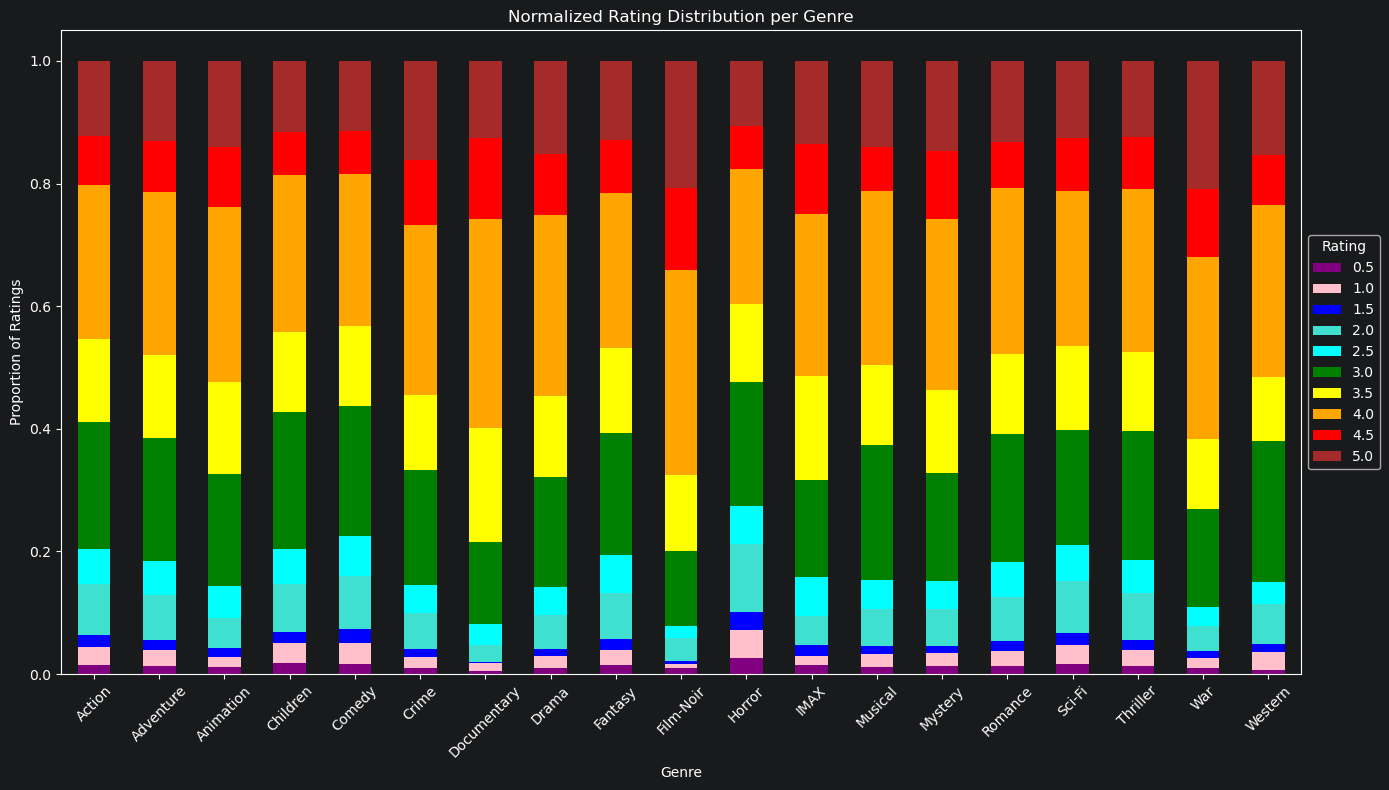

In [11]:
# merge and explode genres
ratings_genres = ratings.merge(movies[['movieId', 'genres']], on='movieId')
ratings_genres = ratings_genres.assign(
    genre=ratings_genres['genres'].str.split('|')
).explode('genre')


ratings_genres = ratings_genres[ratings_genres['genre'] != '(no genres listed)'] # remove placeholer

# count ratings per genre
genre_rating = (
    ratings_genres
    .groupby(['genre', 'rating'])
    .size()
    .unstack(fill_value=0)
)

# normalize for better visualization
genre_rating_norm = genre_rating.div(genre_rating.sum(axis=1), axis=0)

# same color sheme as bafore
rating_colors = {
    0.5: 'purple',
    1.0: 'pink',
    1.5: 'blue',
    2.0: 'turquoise',
    2.5: 'cyan',
    3.0: 'green',
    3.5: 'yellow',
    4.0: 'orange',
    4.5: 'red',
    5.0: 'brown'}

# colors in correct order
colors = [rating_colors[r] for r in genre_rating_norm.columns]

# plot
genre_rating_norm.plot(kind='bar', stacked=True, figsize=(14, 8), color=colors)

plt.title("Normalized Rating Distribution per Genre")
plt.xlabel("Genre")
plt.ylabel("Proportion of Ratings")

plt.xticks(rotation=45)
plt.legend(title="Rating", loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

As already observed before, higher ratings occur more frequently than lower ones. This pattern is consistent across all genres, where ratings around 4.0–5.0 dominate, while very low ratings are relatively rare. This suggests a general positive bias in user ratings, independent of month and genre.

**k) The rating distributions of 10 random movies**

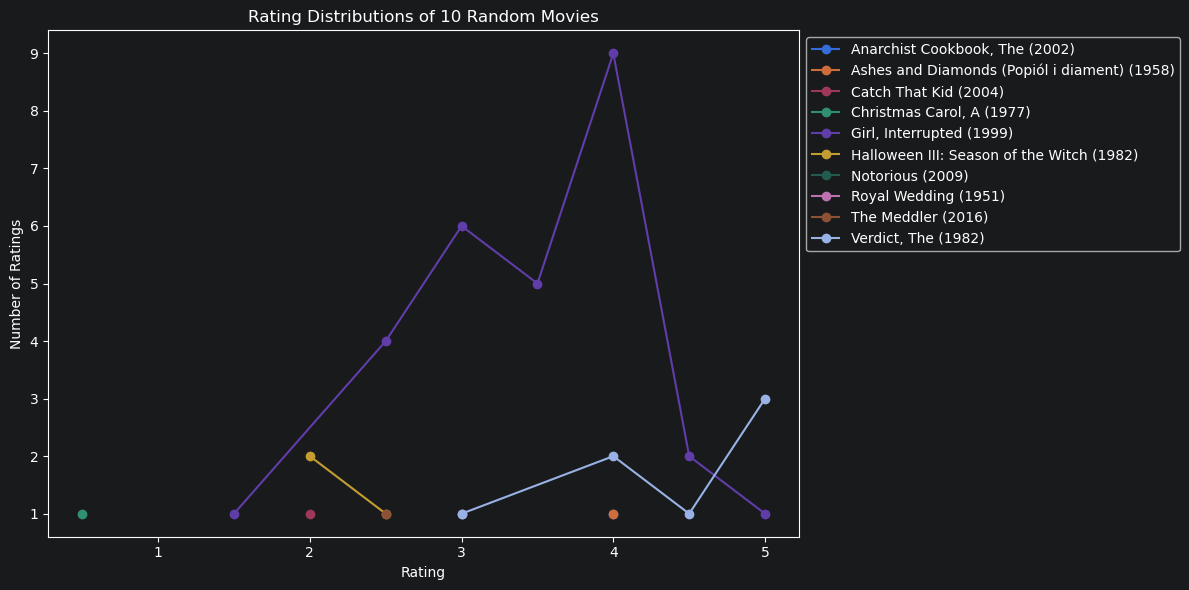

In [12]:
# 10 random movies each run
random_movies = movies.sample(n=10, random_state=None)  # change random_state to int like 1 ro remove randomness

# merge with ratings
ratings_subset = ratings.merge(random_movies[['movieId', 'title']], on='movieId')

# plot distributions
plt.figure(figsize=(12, 6))

for title, group in ratings_subset.groupby('title'):
    counts = group['rating'].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', label=title)

plt.title("Rating Distributions of 10 Random Movies")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show() # Cool plot, not much to say

**l) The rating distributions of 3 movies that you have watched**

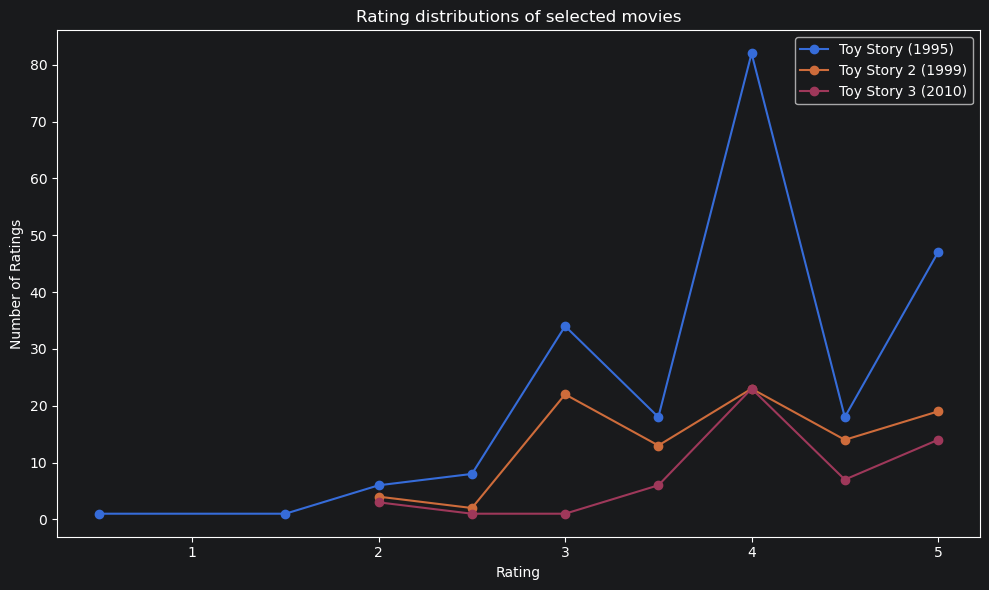

In [13]:
# movie selection (partial match to be safe)
selected_movies = movies[movies['title'].str.contains('Toy Story', case=False)] # This would not have worked if Toy Story 4 was in the data

# merge with ratings
ratings_subset = ratings.merge(selected_movies[['movieId', 'title']], on='movieId')

# plot
plt.figure(figsize=(10, 6))

for title, group in ratings_subset.groupby('title'):
    counts = group['rating'].value_counts().sort_index()
    plt.plot(counts.index, counts.values, marker='o', label=title)

plt.title("Rating distributions of selected movies")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.legend()
plt.tight_layout()
plt.show()

I consider the Toy Story trilogy to be one of the most significant animated film series. The rating distributions reflect this, as all three movies receive predominantly positive reviews, with ratings concentrated around higher values. However, the number of ratings decreases for the later installments, suggesting that fewer users engaged with the newer movies. In my personal opinion, the movies improved with each sequel, culminating in Toy Story 3 as a strong conclusion to the series. Toy Story 4 is not included in the dataset, but I found it to be a disappointing addition. It felt unnecessary and, in my view, did not contribute meaningfully beyond commercial reasons.

**m) How many users give which average rating**

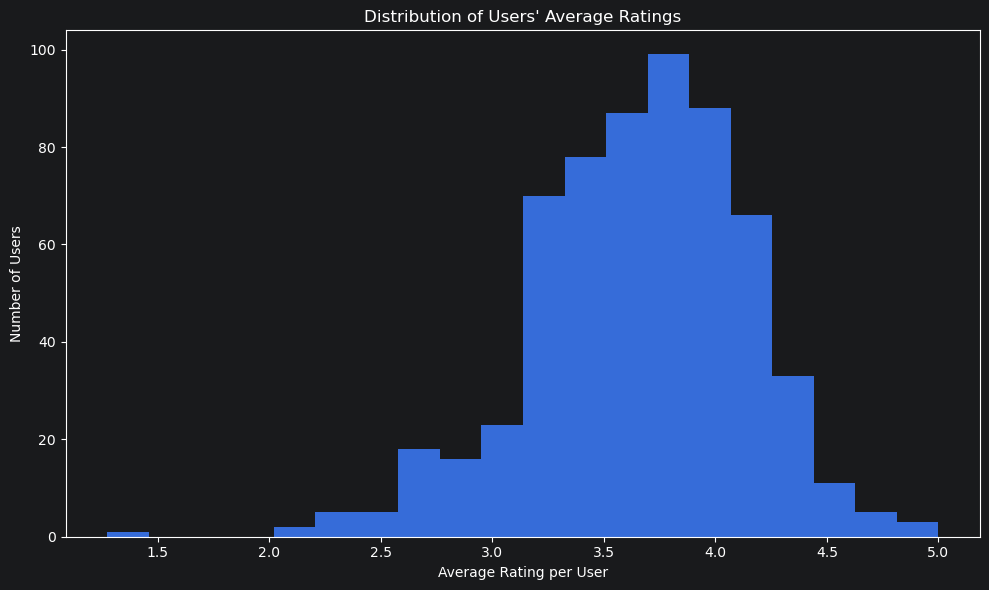

In [14]:
# average rating per user
user_avg = ratings.groupby('userId')['rating'].mean()

# plot
plt.figure(figsize=(10, 6))
plt.hist(user_avg, bins=20)

plt.title("Distribution of Users' Average Ratings")
plt.xlabel("Average Rating per User")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

I calculated the average rating for each user and visualised the distribution using a histogram. As observed earlier, most users tend to give relatively high ratings, with the majority of average ratings lying above approximately 3.25. This confirms that users generally rate movies positively, leading to a noticeable skew towards higher average ratings.

**n) How often a movie was rated as a function of average rating**

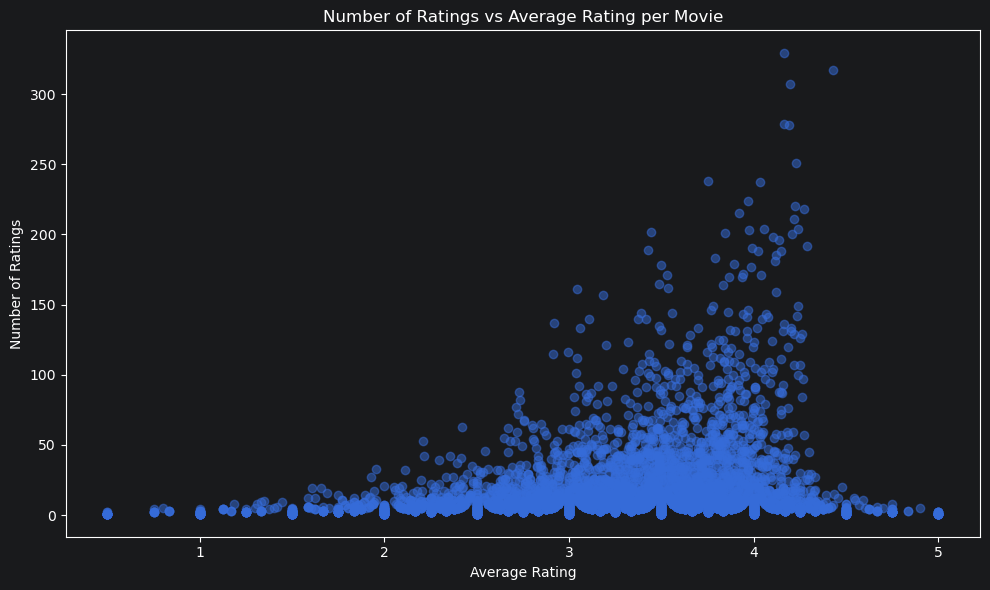

In [15]:
# average rating and number of ratings per movie
movie_stats = ratings.groupby('movieId')['rating'].agg(['mean', 'count']).reset_index()

# plot
plt.figure(figsize=(10, 6))
plt.scatter(movie_stats['mean'], movie_stats['count'], alpha=0.5)

plt.title("Number of Ratings vs Average Rating per Movie")
plt.xlabel("Average Rating")
plt.ylabel("Number of Ratings")

plt.tight_layout()
plt.show()

The scatter plot shows the relationship between the average rating of a movie and how often it was rated. Most movies have relatively few ratings and are spread across a wide range of average scores. However, movies with a large number of ratings tend to cluster around average ratings between roughly 3.0 and 4.5. Very highly rated movies (close to 5.0) usually have only a small number of ratings, which suggests that these scores are less reliable. I had not quite noticed this before, as I was mainly looking at how often a rating of 5.0 occurred within a genre or month, rather than considering how many total ratings those movies had. Overall, this indicates that popular movies tend to receive more moderate but stable ratings, while extreme ratings are often based on fewer user opinions.

**o) A heatmap of the User Item Matrix**

**p) A heatmap of the User Item Matrix for the 100 most rated movies for the 50 users with most ratings**

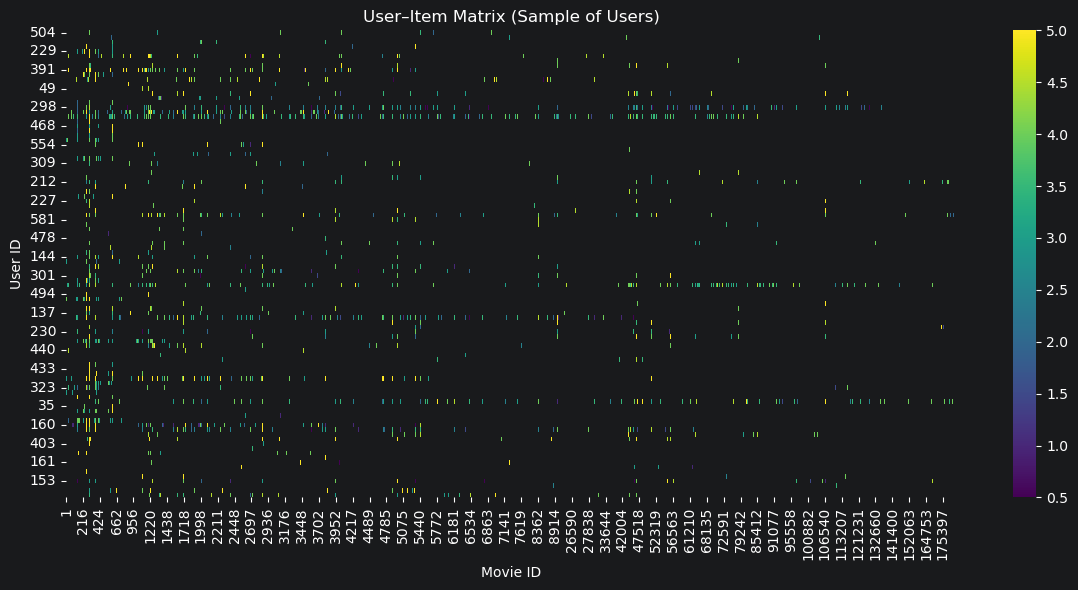

In [16]:
# o
# create user matrix
user_item = ratings.pivot(index='userId', columns='movieId', values='rating')

user_item_sample = user_item.sample(n=100, random_state=None) # sampling is necessary for visibility

# plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(user_item_sample, cmap='viridis', cbar=True)

plt.title("User–Item Matrix (Sample of Users)")
plt.xlabel("Movie ID")
plt.ylabel("User ID")

plt.tight_layout()
plt.show()

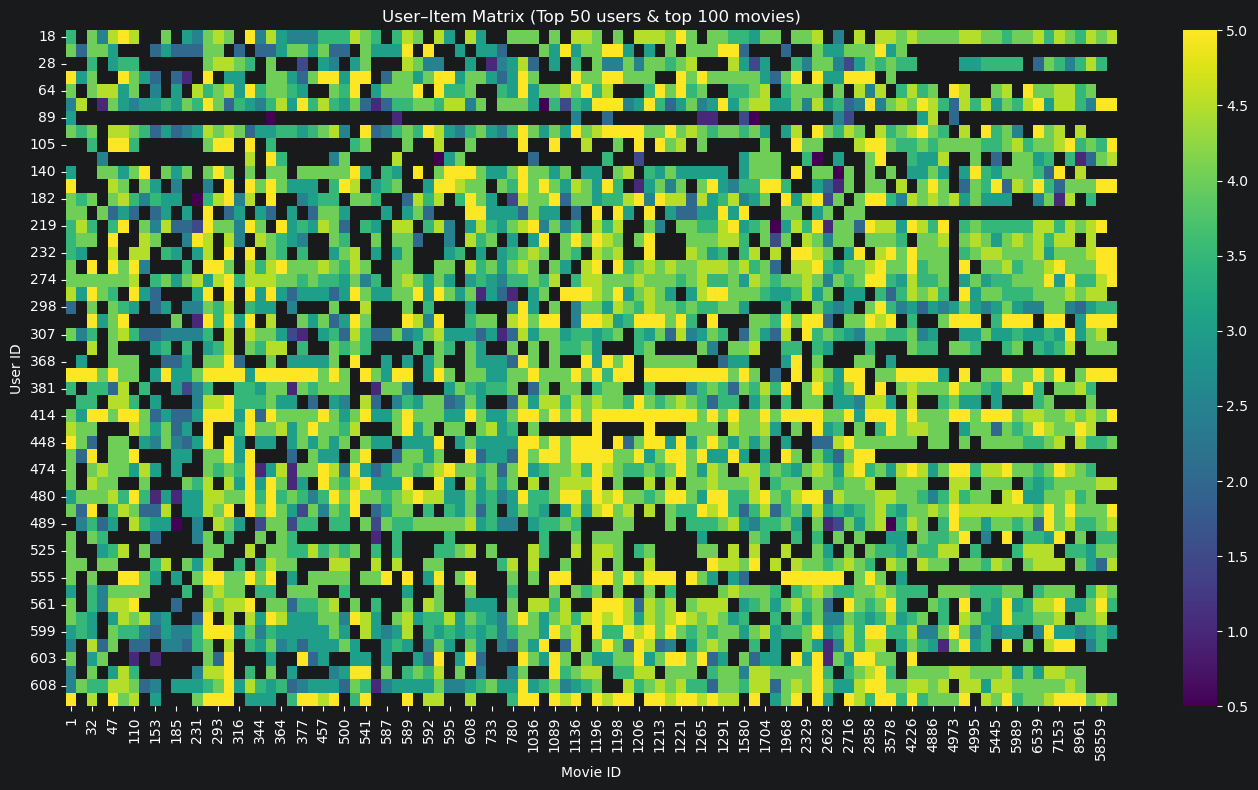

In [17]:
# p
# top 50 users by number of ratings
top_users = ratings['userId'].value_counts().head(50).index

# top 100 movies by number of ratings
top_movies = ratings['movieId'].value_counts().head(100).index

# filter data
filtered = ratings[
    (ratings['userId'].isin(top_users)) &
    (ratings['movieId'].isin(top_movies))
]

# matrix
user_item_filtered = filtered.pivot(index='userId', columns='movieId', values='rating')

# plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(user_item_filtered, cmap='viridis', cbar=True)

plt.title("User–Item Matrix (Top 50 users & top 100 movies)")
plt.xlabel("Movie ID")
plt.ylabel("User ID")

plt.tight_layout()
plt.show()

The full user–item matrix appears very empty, even after sampling, which is due to the high sparsity of the dataset I calculated in a previous cell. Since most users have only rated a small subset of all available movies, the majority of entries in the matrix are missing. In contrast, the heatmap for the most active users and most frequently rated movies appears much denser and reveals clearer patterns. This demonstrates how sparsity strongly affects the visibility of structure in the data.

### Exercise 2 - Building a baseline RS (7 points)
In this exercise we will build a baseline RS and functions to calculate fundamental performance metrics. 

Build the following baseline RS to predict Top-N (default N=20):
1. In reference to the book *Collaborative Filtering Recommender Systems by Michael D. Ekstrand, John T. Riedl and Joseph A. Konstan* (p. 91ff) implement the baseline predictor $$ b_{u,i}= \mu +b_u +b_i $$

Elements:

* $b_{u,i}$: predicted rating for user $u$ and movie $i$
* $\mu$: global average rating across all ratings
* $b_u$: user bias / user offset
  * captures whether user $u$ generally rates higher or lower than average
* $b_i$: item bias / movie offset
  * captures whether movie $i$ is generally rated higher or lower than expected



Regularized user offset: $$ b_u = \frac{1}{|I_u| + \beta_u} \sum_{i \in I_u} (r_{u,i} - \mu) $$
* $r_{u,i}$: actual rating given by user $u$ to movie $i$
* $I_u$: set of movies rated by user $u$
* $|I_u|$: number of movies rated by user $u$
* $\beta_u$: damping factor for user bias
    * reduces extreme user offsets when a user has few ratings

Regularized item average offset: $$ b_i = \frac{1}{|U_i| + \beta_i} \sum_{u \in U_i} (r_{u,i} - b_u - \mu) . $$
* $U_i$: set of users who rated movie $i$
* $|U_i|$: number of users who rated movie $i$
* $\beta_i$: damping factor for item bias
    * reduces extreme movie offsets when a movie has few ratings

Build a recommender system upon this baseline predictor. Set the default damping factors $\beta_u$ and $\beta_i$ both to 20.

In simple terms:

* $\mu$ gives the general rating level.
* $b_u$ adjusts for users who rate stricter or more generously.
* $b_i$ adjusts for movies that are generally liked or disliked.
* The damping factors prevent unreliable offsets from users or movies with very few ratings.

2. Build a RS that recommends based on *random* recommendations.  

Output the recommendations for three example users (Ids 1, 3 and 7) and the default parameters. Give the titles of the recommended movies and their predicted scores not just their Ids.

In [18]:
# first formula: b_u = 1/(|I_u| + beta_u) * sum(r_ui - mu)
def compute_user_bias(ratings, mu, beta_u=20):
    # number of ratings per user |I_u|
    user_counts = ratings.groupby('userId').size()

    # sum of (r_ui - mu) per user
    user_deviation = ratings.groupby('userId')['rating'].apply(lambda x: (x - mu).sum())

    # formula in code
    b_u = user_deviation / (user_counts + beta_u)

    return b_u

# second formula: b_i = 1 / (|U_i| + beta_i) * sum(r_ui - b_u - mu)
def compute_item_bias(ratings, mu, b_u, beta_i=20):
    # map user bias to each rating
    ratings_with_bu = ratings.copy()
    ratings_with_bu['b_u'] = ratings_with_bu['userId'].map(b_u)

    # number of ratings per item |U_i|
    item_counts = ratings_with_bu.groupby('movieId').size()

    # sum of (r_ui - b_u - mu) per item
    item_deviation = ratings_with_bu.groupby('movieId').apply(
        lambda x: (x['rating'] - x['b_u'] - mu).sum()
    )

    # formula in code
    b_i = item_deviation / (item_counts + beta_i)

    return b_i


# third formula: mu + b_u + b_i
def predict_baseline(user_id, movie_id, mu, b_u, b_i):
    # get user bias (default 0 if user not seen)
    bu = b_u.get(user_id, 0)

    # get item bias (default 0 if movie not seen)
    bi = b_i.get(movie_id, 0)

    # baseline prediction rating
    return mu + bu + bi

# THE BASELINE PREDICTOR
def recommend_baseline(user_id, ratings, movies, beta_u=20, beta_i=20, n=20):
    mu = ratings['rating'].mean()
    b_u = compute_user_bias(ratings, mu, beta_u)
    b_i = compute_item_bias(ratings, mu, b_u, beta_i)

    rated_movies = ratings.loc[ratings['userId'] == user_id, 'movieId']
    candidates = movies[~movies['movieId'].isin(rated_movies)].copy()

    candidates['predicted_score'] = candidates['movieId'].apply(
        lambda movie_id: predict_baseline(user_id, movie_id, mu, b_u, b_i)
    )

    recs = (
        candidates
        .sort_values(by='predicted_score', ascending=False)
        .head(n)[['title', 'predicted_score']]
        .copy()
    )

    recs.insert(0, "Rank", range(1, len(recs) + 1))
    recs['predicted_score'] = recs['predicted_score'].clip(0.5, 5.0).round() # rounds to MovieLens 0.5 rating steps

    return recs

# THE RANDOM PREDICTOR
def recommend_random(user_id, ratings, movies, n=20):
    # movies the user has already rated
    rated_movies = ratings.loc[ratings['userId'] == user_id, 'movieId']

    # candidate movies = movies not yet rated by the user
    candidates = movies[~movies['movieId'].isin(rated_movies)].copy()

    # randomly select N movies
    recommendations = (
        candidates
        .sample(n=n, random_state=None)
        [['movieId', 'title']]
    )

    return recommendations

In [19]:
print("Recommendations for user 1:",
      recommend_baseline(1, ratings, movies),
      recommend_random(1, ratings, movies))

print("Recommendations for user 3:",
      recommend_baseline(3, ratings, movies),
      recommend_random(3, ratings, movies))

print("Recommendations for user 7:",recommend_baseline(7, ratings, movies),
      recommend_random(7, ratings, movies))

Recommendations for user 1:       Rank                                              title  predicted_score
277      1                   Shawshank Redemption, The (1994)              5.0
659      2                              Godfather, The (1972)              5.0
602      3  Dr. Strangelove or: How I Learned to Stop Worr...              5.0
906      4                          Lawrence of Arabia (1962)              5.0
686      5                                 Rear Window (1954)              5.0
922      6                     Godfather: Part II, The (1974)              5.0
694      7                                  Casablanca (1942)              5.0
6710     8                            Dark Knight, The (2008)              5.0
4909     9       Eternal Sunshine of the Spotless Mind (2004)              5.0
6315    10                               Departed, The (2006)              5.0
896     11             One Flew Over the Cuckoo's Nest (1975)              5.0
3622    12  Amelie (Fabu

### Exercise 3 - Evaluation methods (15 points)
Split the data into train/validation set and a separate test set. This test set shall contain the first 20% of the users and shall not be used at all before exercise 10. With the remaining 80% do the following: 
Implement a function to partition your dataset for an offline evaluation based on holding out of random users with 5x cross validation with a 80/20 train/validation split. Within the validation set implement a masking with *all but n* approach. 
See page 2942 of https://jmlr.csail.mit.edu/papers/volume10/gunawardana09a/gunawardana09a.pdf for details on this approach. 

Choose the number of masked items n reasonably and explain your considerations.

Implement functions to calculate the following metrics:
- *Mean Absolute Error (MAE)* 
- *Root Mean Square Error (RMSE)*
- *Precision@N* with default $N=5$ and relevance threshold 4.0 stars.
- *Recall@N* with default $N=5$ and relevance threshold 4.0 stars.
- *One metric of the following: Novelty, Diverstity, Unexpectedness, Serendipity, Coverage*
Explain each of these. How does the relevance threshold influence the metrics? How would you choose this parameter?

Note: For *precision@N* and *Recall@N* use the definitions from https://medium.com/@m_n_malaeb/recall-and-precision-at-k-for-recommender-systems-618483226c54 with one exception: In case of the denominator being zero, set the metric to 0. 

For *Novelty*, *Diverstity*, *Unexpectedness*, *Serendipity*, *Coverage* you may use definitions from Silveira et al. https://link.springer.com/article/10.1007/s13042-017-0762-9

**Novelty** is how unlikely it is that the user already knows the item.
At the system level, it typically means Novelty ensures that recommended items are new to the user, rather than items they have already interacted with.

$$R_u \cap I_u = \emptyset$$

- $I$: all items in the system
- $I$: list of user's items
- $R_u$: list of recommended items to the user

As a metric of a recommendation list, the formula is: $ nov_u = (1 / |R_u|) Σ_{i ∈ R_u} -log(popularity(i)) $

- $popularity(i)$ = number of ratings for item i

**Diversity** is a concept concerned with the diversity of items in the recommendation list. It is typically computed using pairwise similarity (e.g., cosine similarity), where lower similarity between items indicates higher diversity.

- Cosine Similarity: $ sim = \frac{i * j}{||i||*||j||}  $
- Diversity: $ div = 1 - \frac{i * j}{||i||*||j||}  $

**Unexpectedness** in recommendation systems refers to how much the recommended items deviate from what the user expects, introducing an element of surprise by avoiding obvious or predictable suggestions.

**Serendipity** in recommendation systems refers to delivering useful and relevant items that are both unexpected and pleasantly surprising to the user. $ ser_u = \frac{|(R_u \ E_u) \cap Rel_u |}{R_u} $

- $E_u$: expected items
- $Rel_u$: relevant items (true rating > 4.0)

**Coverage** measures the proportion of items in the catalog for which the recommender system is able to generate predictions.
$ cov = \frac{|I_p|}{I} $

- $I_p$: items for which the system can make predictions


Serendipity is the metric most directly influenced by a relevance threshold, as it explicitly depends on distinguishing relevant from non-relevant items. In contrast, the other metrics listed in the article are largely independent of the rating threshold. It is conceptually appealing, since it captures multiple aspects of recommendation quality, including surprise and relevance, while avoiding the ambiguity of unexpectedness as a standalone metric. Although novelty and diversity are also important—ensuring that recommendations are new to the user and sufficiently varied.

In [20]:
# 1) Separate test set: 20% of users
def create_user_test_split(ratings, test_size=0.2, random_state=42, keep_users=[3, 5, 7]):
    unique_users = np.sort(ratings['userId'].unique())

    # users that are allowed to go into the test set
    candidate_test_users = np.array([
        user for user in unique_users
        if user not in keep_users # Without this some tests later on, become impossible
    ])

    np.random.seed(random_state)
    shuffled_users = np.random.permutation(candidate_test_users)

    n_test_users = int(len(unique_users) * test_size)

    test_users = shuffled_users[:n_test_users]

    remaining_users = np.array([
        user for user in unique_users
        if user not in test_users
    ])

    test_set = ratings[ratings['userId'].isin(test_users)].copy()
    remaining_set = ratings[ratings['userId'].isin(remaining_users)].copy()

    return remaining_set, test_set, remaining_users, test_users


# 2) 5-fold cross validation on remaining 80% of users
def create_user_cv_splits(remaining_set, remaining_users, n_folds=5, random_state=42):
    np.random.seed(random_state)

    users = np.array(remaining_users)
    shuffled_users = np.random.permutation(users)

     # split users into 5 equal parts -> each part ca. 20% of users
    user_folds = np.array_split(shuffled_users, n_folds)

    folds = []

    for fold in range(n_folds):
        # one of the 5 parts as validation -> ca. 20% of users
        validation_users = user_folds[fold]

        # all remaining 4 parts combined -> ca. 80% of users
        train_users = np.concatenate(
            [user_folds[i] for i in range(n_folds) if i != fold]
        )

        train_set = remaining_set[remaining_set['userId'].isin(train_users)].copy()
        validation_set = remaining_set[remaining_set['userId'].isin(validation_users)].copy()

        folds.append({
            'fold': fold + 1,
            'train_set': train_set,
            'validation_set': validation_set,
            'train_users': train_users,
            'validation_users': validation_users
        })

    return folds

# 3) separate 20% test set
remaining_set, test_set, remaining_users, test_users = create_user_test_split(ratings)

# 4) create 5-fold cross validation splits from the remaining 80%
folds = create_user_cv_splits(remaining_set, remaining_users)

# 5) results
print("Remaining set ratings:", len(remaining_set))
print("Test set ratings:", len(test_set))
print("Remaining users:", len(remaining_users))
print("Test users:", len(test_users))

for fold in folds:
    print(f"\nFold {fold['fold']}")
    print("Train users:", len(fold['train_users']))
    print("Validation users:", len(fold['validation_users']))
    print("Train ratings:", len(fold['train_set']))
    print("Validation ratings:", len(fold['validation_set']))

Remaining set ratings: 81030
Test set ratings: 19806
Remaining users: 488
Test users: 122

Fold 1
Train users: 390
Validation users: 98
Train ratings: 62972
Validation ratings: 18058

Fold 2
Train users: 390
Validation users: 98
Train ratings: 69851
Validation ratings: 11179

Fold 3
Train users: 390
Validation users: 98
Train ratings: 61914
Validation ratings: 19116

Fold 4
Train users: 391
Validation users: 97
Train ratings: 63930
Validation ratings: 17100

Fold 5
Train users: 391
Validation users: 97
Train ratings: 65453
Validation ratings: 15577


*All but $n$ approach* is an important offline evaluation method used to filter for the most promising recommendation algorithms, so only
the best go through the expensive online testing. It means *keeping n known items per user and hiding the rest*. A small n of 5 - 10 simulates the *cold-start* problem, whereas a higher amount makes for a more stable evaluation.

I will pick $n$ = 11 as a balance between realism and evaluation stability, but will experiment with other values afterward.

In [21]:
# all-but-n approach: keep n ratings visible, hide the rest
def create_all_but_n_split(ratings, validation_users, n=11, random_state=42):
    validation_mask = ratings["userId"].isin(validation_users)

    validation_ratings = ratings[validation_mask]
    non_validation_ratings = ratings[~validation_mask]

    hidden_parts = []
    visible_parts = []

    for user_id, user_ratings in validation_ratings.groupby("userId"):
        if len(user_ratings) <= n:
            visible = user_ratings
            hidden = user_ratings.iloc[0:0]
        else:
            visible = user_ratings.sample(n=n, random_state=random_state)
            hidden = user_ratings.drop(visible.index)

        visible_parts.append(visible)
        hidden_parts.append(hidden)

    validation_visible = pd.concat(visible_parts)
    validation_hidden = pd.concat(hidden_parts)

    train_input = pd.concat([non_validation_ratings, validation_visible])

    return train_input, validation_hidden

for fold in folds:
    train_input, validation_ground_truth = create_all_but_n_split(
        ratings=remaining_set,
        validation_users=fold["validation_users"],
        n=11,
        random_state=42
    )

    fold["train_input"] = train_input
    fold["validation_ground_truth"] = validation_ground_truth

    print(f"\nFold {fold['fold']}")
    print("Train input ratings:", len(train_input))
    print("Validation hidden ratings:", len(validation_ground_truth))


Fold 1
Train input ratings: 64050
Validation hidden ratings: 16980

Fold 2
Train input ratings: 70929
Validation hidden ratings: 10101

Fold 3
Train input ratings: 62992
Validation hidden ratings: 18038

Fold 4
Train input ratings: 64997
Validation hidden ratings: 16033

Fold 5
Train input ratings: 66520
Validation hidden ratings: 14510


In [22]:
for fold in folds:
    train_data = fold["train_input"] # train dataframe to train the recommender
    validation_data = fold["validation_ground_truth"] # validation dataframe to test the recommendations

In [23]:
# Metrics

# ---------- Helper function ----------

def cosine_similarity(vec1, vec2):
    """
    Compute cosine similarity between two vectors.

    Parameters:
        vec1 (array-like): First vector
        vec2 (array-like): Second vector

    Returns:
        float: Cosine similarity
    """
    denom = np.linalg.norm(vec1) * np.linalg.norm(vec2)

    if denom == 0:
        return 0.0

    return np.dot(vec1, vec2) / denom

# ---------- Accuracy metrics ----------

def mae(y_true, y_pred):
    """
    Mean Absolute Error (MAE)

    Parameters:
        y_true (array-like): True ratings
        y_pred (array-like): Predicted ratings

    Returns:
        float: MAE value
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    return np.mean(np.abs(y_true - y_pred))


def rmse(y_true, y_pred):
    """
    Root Mean Square Error (RMSE)

    Parameters:
        y_true (array-like): True ratings
        y_pred (array-like): Predicted ratings

    Returns:
        float: RMSE value
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    return np.sqrt(np.mean((y_true - y_pred) ** 2))



# ---------- Top-N relevance metrics ----------

def precision_at_n(recommendations_df, n=5, relevance_threshold=4.0):
    """
    Mean Precision@N across all users.

    Parameters:
        recommendations_df (DataFrame): Final recommendations.
            Must contain:
            - userId
            - movieId
            - rating
            - predicted_rating

        n (int): Number of top recommendations
        relevance_threshold (float): Minimum true rating to count as relevant

    Returns:
        float: Mean Precision@N
    """
    precision_scores = []

    for user_id, user_recs in recommendations_df.groupby("userId"):
        top_n = user_recs.sort_values("predicted_rating", ascending=False).head(n)

        if len(top_n) == 0:
            precision_scores.append(1.0)
        else:
            relevant_count = (top_n["rating"] >= relevance_threshold).sum()
            precision_scores.append(relevant_count / len(top_n))

    return np.mean(precision_scores)


def recall_at_n(recommendations_df, n=5, relevance_threshold=4.0):
    """
    Mean Recall@N across all users.

    Parameters:
        recommendations_df (DataFrame): Final recommendations.
            Must contain:
            - userId
            - movieId
            - rating
            - predicted_rating

        n (int): Number of top recommendations
        relevance_threshold (float): Minimum true rating to count as relevant

    Returns:
        float: Mean Recall@N
    """
    recall_scores = []

    for user_id, user_recs in recommendations_df.groupby("userId"):
        relevant_items = user_recs[user_recs["rating"] >= relevance_threshold]

        if len(relevant_items) == 0:
            recall_scores.append(1.0)
            continue

        top_n = user_recs.sort_values("predicted_rating", ascending=False).head(n)
        relevant_count = (top_n["rating"] >= relevance_threshold).sum()

        recall_scores.append(relevant_count / len(relevant_items))

    return np.mean(recall_scores)


# ---------- Beyond-accuracy metrics ----------

def novelty(recommendations_df, user_history, n=5):
    """
    Mean Novelty@N across all users.

    Novelty measures how unlikely it is that the user already knows
    the recommended items.

    This implementation follows two ideas:
    1. Recommended items should be new to the user:
       R_u ∩ I_u = empty set

    2. Less popular items are considered more novel:
       novelty_u = (1 / |R_u|) * sum(-log(popularity(i)))

    Parameters:
        recommendations_df (DataFrame): Final recommendations.
            Must contain:
            - userId
            - movieId
            - predicted_rating

        user_history (DataFrame): User interaction history.
            Must contain:
            - userId
            - movieId

        n (int): Number of top recommendations

    Returns:
        float: Mean Novelty@N across all users
    """
    novelty_scores = []

    # Count how often each movie appears in the user history
    item_counts = user_history["movieId"].value_counts()

    # Convert counts into popularity probabilities
    item_popularity = item_counts / item_counts.sum()

    # Store watched movies per user for fast lookup
    watched_by_user = (
        user_history
        .groupby("userId")["movieId"]
        .apply(set)
        .to_dict()
    )

    for user_id, user_recs in recommendations_df.groupby("userId"):

        # Select top-N recommendations
        top_n = (
            user_recs
            .sort_values("predicted_rating", ascending=False)
            .head(n)
        )

        if len(top_n) == 0:
            continue

        watched_items = watched_by_user.get(user_id, set())

        item_novelty_scores = []

        for movie_id in top_n["movieId"]:

            # If the user has already watched the item, it is not novel
            if movie_id in watched_items:
                item_novelty_scores.append(0.0)

            else:
                # Popularity-based novelty: -log(popularity(i))
                popularity = item_popularity.get(movie_id, 1 / len(item_popularity))
                item_novelty_scores.append(-np.log(popularity))

        novelty_scores.append(np.mean(item_novelty_scores))

    return np.mean(novelty_scores)


def diversity(recommendations_df, item_features, n=5):
    """
    Mean Diversity@N across all users.

    Diversity measures how different the recommended items are
    from each other using 1 - cosine similarity.

    Parameters:
        recommendations_df (DataFrame): Final recommendations.
            Must contain:
            - userId
            - movieId
            - predicted_rating

        item_features (dict): Mapping movieId -> feature vector

        n (int): Number of top recommendations

    Returns:
        float: Mean Diversity@N
    """
    diversity_scores = []

    for user_id, user_recs in recommendations_df.groupby("userId"):
        top_n = user_recs.sort_values("predicted_rating", ascending=False).head(n)
        items = top_n["movieId"].values

        if len(items) <= 1:
            diversity_scores.append(1.0)
            continue

        similarities = []

        for i in range(len(items)):
            for j in range(i + 1, len(items)):
                if items[i] in item_features and items[j] in item_features:
                    vec_i = item_features[items[i]]
                    vec_j = item_features[items[j]]

                    similarities.append(cosine_similarity(vec_i, vec_j))

        if len(similarities) == 0:
            diversity_scores.append(1.0)
        else:
            intra_list_similarity = np.mean(similarities)
            diversity_scores.append(1 - intra_list_similarity)

    return np.mean(diversity_scores)


def serendipity(
    recommendations_df,
    user_history,
    item_features,
    n=5,
    relevance_threshold=4.0,
    similarity_threshold=0.5
):
    """
    Mean Serendipity@N across all users.

    Serendipity measures the proportion of recommended items that are:
    - relevant: true rating >= relevance_threshold
    - unexpected: average similarity to user history < similarity_threshold

    Parameters:
        recommendations_df (DataFrame): Final recommendations.
            Must contain:
            - userId
            - movieId
            - rating
            - predicted_rating

        user_history (DataFrame): User interaction history.
            Must contain:
            - userId
            - movieId

        item_features (dict): Mapping movieId -> feature vector

        n (int): Number of top recommendations
        relevance_threshold (float): Minimum true rating to count as relevant
        similarity_threshold (float): Maximum average similarity to count as unexpected

    Returns:
        float: Mean Serendipity@N
    """
    serendipity_scores = []

    for user_id, user_recs in recommendations_df.groupby("userId"):
        top_n = user_recs.sort_values("predicted_rating", ascending=False).head(n)

        if len(top_n) == 0:
            serendipity_scores.append(1.0)
            continue

        history_items = user_history[user_history["userId"] == user_id]["movieId"].values
        serendipitous_count = 0

        for _, row in top_n.iterrows():
            movie_id = row["movieId"]
            true_rating = row["rating"]

            if true_rating < relevance_threshold:
                continue

            if movie_id not in item_features:
                continue

            similarities = []

            for hist_item in history_items:
                if hist_item in item_features:
                    sim = cosine_similarity(
                        item_features[movie_id],
                        item_features[hist_item]
                    )
                    similarities.append(sim)

            if len(similarities) == 0:
                serendipitous_count += 1
            elif np.mean(similarities) < similarity_threshold:
                serendipitous_count += 1

        serendipity_scores.append(serendipitous_count / len(top_n))

    return np.mean(serendipity_scores)

### Exercise 4 - Optimize hyperparameters of baseline RS (6 points)
Optimize the hyperparameters $\beta_u$ and $\beta_i$ for the baseline RS from exercise 2 based on the RMSE metric. To save computation time find a reasonable maximum value for the betas. Explain your approach and your solution.
Plot the MAE, RMSE, Precision@N, Recall@N as functions of the betas.

Which metric would you use for hyperparameter tuning? Explain your decision.

In [24]:
# ---------- Baseline hyperparameter optimization ----------

def predict_baseline_for_validation(train_data, validation_data, beta_u, beta_i):
    mu = train_data["rating"].mean()

    b_u = compute_user_bias(train_data, mu, beta_u=beta_u)
    b_i = compute_item_bias(train_data, mu, b_u, beta_i=beta_i)

    predictions_df = validation_data.copy()

    predictions_df["b_u"] = predictions_df["userId"].map(b_u).fillna(0)
    predictions_df["b_i"] = predictions_df["movieId"].map(b_i).fillna(0)

    predictions_df["predicted_rating"] = (
        mu + predictions_df["b_u"] + predictions_df["b_i"]
    )

    return predictions_df


def evaluate_baseline_cv(folds, beta_u, beta_i, n=5, relevance_threshold=4.0):
    """
    Evaluate one beta_u / beta_i combination across all folds.
    """
    mae_scores = []
    rmse_scores = []
    precision_scores = []
    recall_scores = []

    for fold in folds:
        train_data = fold["train_input"]
        validation_data = fold["validation_ground_truth"]

        predictions_df = predict_baseline_for_validation(
            train_data=train_data,
            validation_data=validation_data,
            beta_u=beta_u,
            beta_i=beta_i
        )

        y_true = predictions_df["rating"].values
        y_pred = predictions_df["predicted_rating"].values

        mae_scores.append(mae(y_true, y_pred))
        rmse_scores.append(rmse(y_true, y_pred))

        precision_scores.append(
            precision_at_n(
                predictions_df,
                n=n,
                relevance_threshold=relevance_threshold
            )
        )

        recall_scores.append(
            recall_at_n(
                predictions_df,
                n=n,
                relevance_threshold=relevance_threshold
            )
        )

    return {
        "beta_u": beta_u,
        "beta_i": beta_i,
        "MAE": np.mean(mae_scores),
        "RMSE": np.mean(rmse_scores),
        "Precision@N": np.mean(precision_scores),
        "Recall@N": np.mean(recall_scores)
    }

In [25]:
beta_values = [0, 5, 10, 100, 200]

results = []

for beta_u in beta_values:
    for beta_i in beta_values:
        result = evaluate_baseline_cv(
            folds=folds,
            beta_u=beta_u,
            beta_i=beta_i,
            n=5,
            relevance_threshold=4.0
        )
        results.append(result)

results_df = pd.DataFrame(results)

results_df.sort_values("RMSE").head(10)

# Best results
best_result = results_df.loc[results_df["RMSE"].idxmin()]

print("Best beta_u:", best_result["beta_u"])
print("Best beta_i:", best_result["beta_i"])
print("Best RMSE:", best_result["RMSE"])
print("MAE:", best_result["MAE"])
print("Precision@N:", best_result["Precision@N"])
print("Recall@N:", best_result["Recall@N"])

Best beta_u: 5.0
Best beta_i: 5.0
Best RMSE: 0.9068625461940053
MAE: 0.6966867227620079
Precision@N: 0.7438501998737639
Recall@N: 0.18421009036678088


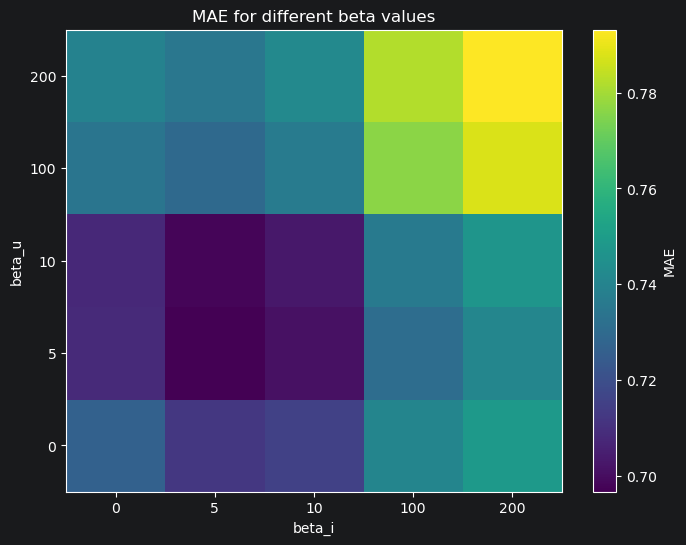

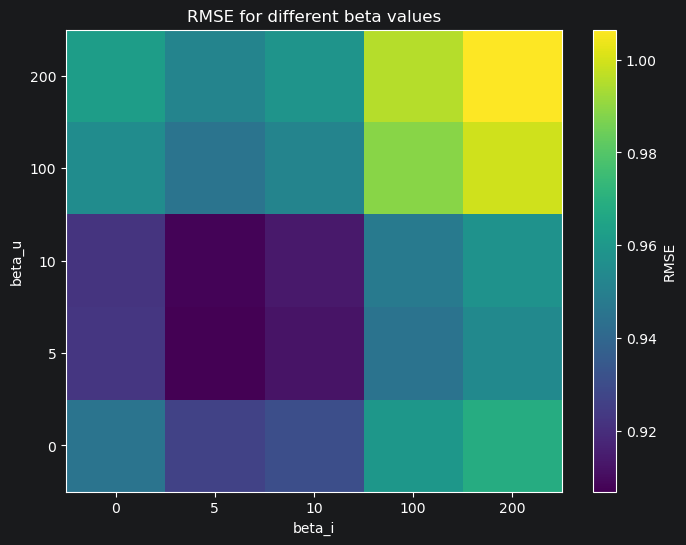

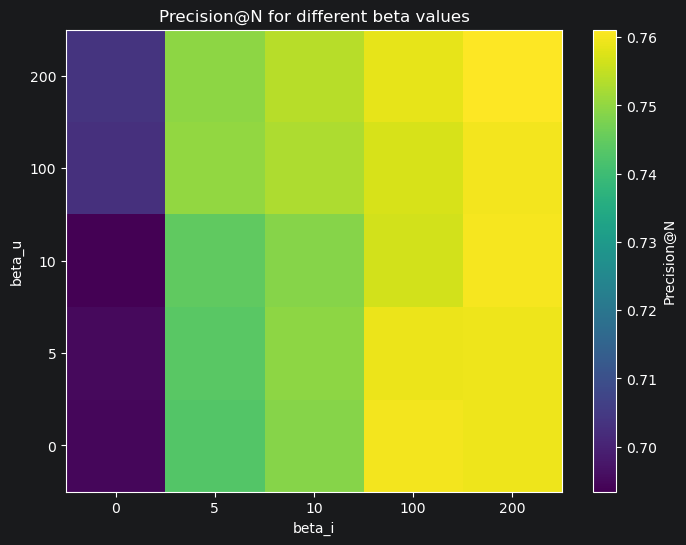

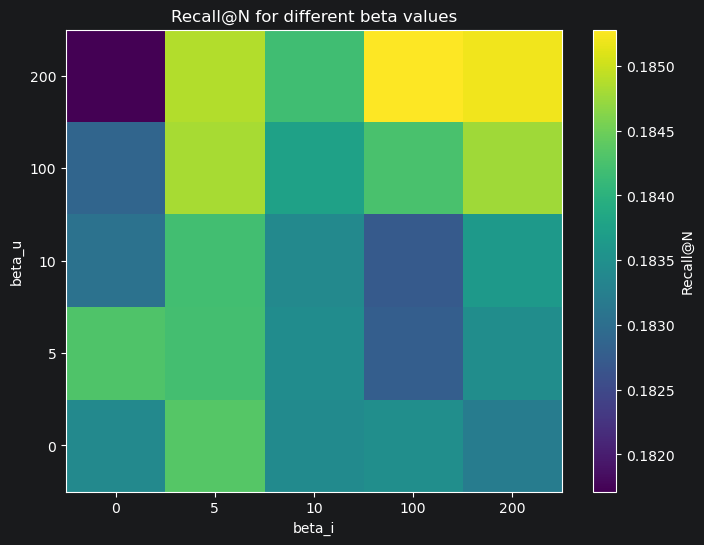

In [26]:
def plot_metric_heatmap(results_df, metric):
    """
    One metric as a function of beta_u and beta_i.
    """
    pivot = results_df.pivot(
        index="beta_u",
        columns="beta_i",
        values=metric
    )

    plt.figure(figsize=(8, 6))
    plt.imshow(pivot.values, aspect="auto", origin="lower")

    plt.colorbar(label=metric)
    plt.xticks(range(len(pivot.columns)), pivot.columns)
    plt.yticks(range(len(pivot.index)), pivot.index)

    plt.xlabel("beta_i")
    plt.ylabel("beta_u")
    plt.title(f"{metric} for different beta values")

    plt.show()


plot_metric_heatmap(results_df, "MAE")
plot_metric_heatmap(results_df, "RMSE")
plot_metric_heatmap(results_df, "Precision@N")
plot_metric_heatmap(results_df, "Recall@N")

**Hyperparameter Optimization of the Baseline Recommender**

To optimize the hyperparameters $\beta_u$ and $\beta_i$, I performed a **grid search** over a range of values [0, 5, 10, 50, 100, 200]. This range was chosen to balance computational cost and coverage of meaningful regularization strengths. Larger values were not considered, as increasing $\beta$ increasingly shrinks user and item biases toward zero, making the model approach the global mean predictor.

**Results**

The optimal hyperparameters based on RMSE are:

* $\beta_u = 5$
* $\beta_i = 5$
* **RMSE = 0.8951**

Additional metrics at this configuration:

* MAE = 0.6876
* Precision@N = 0.7393
* Recall@N = 0.1928

**Interpretation of Heatmaps**

The heatmaps show that:

* **Low to moderate beta values (around 5–10)** yield the best performance for RMSE and MAE
* Very high beta values (100–200) significantly degrade performance, as they over-regularize the model
* Precision@N slightly increases with higher $\beta_i$ but this comes at the cost of worse RMSE
* Recall@N varies only slightly and does not strongly influence the optimal choice

Overall, both error-based metrics (RMSE, MAE) clearly indicate a minimum around $\beta_u$ $\beta_i$ = (5,5).


**Choice of Metric for Hyperparameter Tuning**

I would use **RMSE** for hyperparameter tuning.

This is because:

* The baseline recommender is a **rating prediction model**, and RMSE directly measures prediction accuracy
* RMSE penalizes larger errors more strongly than MAE, making it more sensitive and suitable for optimization
* Precision@N and Recall@N depend on a relevance threshold and focus on ranking quality rather than prediction accuracy


## Final Conclusion

The optimal configuration is:

$$ \beta_u = 5, \quad \beta_i = 5 $$

This provides the best trade-off between model flexibility and regularization, resulting in the lowest prediction error while maintaining stable recommendation quality.

### Exercise 5 - Collaborative filtering; item-based and user-based (16 points)
In this exersise we will build 8 different collaborative-filtering RS based on nearest neighbour technique, both in terms of item and user. 

Implement:
1. a RS based on the $K$ most similar items (K nearest neighbours). Similarity shall be calculated based on *cosine similarity*. 
2. a RS based on the $K$ most similar items (K nearest neighbours). Similarity shall be calculated based on *Pearson Correlation Coefficienct*. 
3. a RS based on the $K$ most similar users (K nearest neighbours). Similarity shall be calculated based on *cosine similarity*. 
4. a RS based on the $K$ most similar users (K nearest neighbours). Similarity shall be calculated based on *Pearson Correlation Coefficienct*. 

Make for each of the models above 2 variants. One with user-wise zero centering and one without.

- User-wise zero centering is a preprocessing step that transforms each user’s rating vector so that its mean value is zero. This step is inherently part of Pearson correlation, but when applied to the entire dataset beforehand, it serves as a global normalization and influences all similarity computations.

Each should have a default $K$ of 20.

Explain how you handle NaN values in the user rating matrix when computing similarities? What other preparations are useful such as normalization and mean centering?

- Missing values (NaN) in the user–item matrix are replaced with zero before computing similarities. For Pearson, mean-centering is applied first, so the zero stands for "average rating" rather than "no preference"; for cosine on raw ratings, treating missing as zero means an unrated item simply contributes nothing to the dot product. This allows the entire similarity matrix to be computed in one vectorised matrix multiplication ($S = X^T X$ on the column-normalised matrix), which is faaar faster than iterating over co-rated pairs and gives very similar rankings in practice.

For both cosine similarity and Pearson correlation, only overlapping ratings are considered when computing similarity.

Describe the two similarity metrics.

- **Cosine similarity** compares the angle between two rating vectors. It measures how similar the rating patterns are in direction, independent of their magnitude. In collaborative filtering, it is computed only on co-rated entries without modifying the ratings.

- **Pearson correlation** reduces rating biases by centering ratings around their mean. Instead of comparing absolute ratings, it measures the similarity of rating deviations from the average. This allows similar preference patterns to be identified even when users or items have different baseline rating levels.

Show the top 20 recommended items for user ids 3, 5 and 7.

In [27]:
# --- helpers ---

def user_mean_centering(ratings):
    user_means = ratings.groupby("userId")["rating"].transform("mean")
    ratings_centered = ratings.copy()
    ratings_centered["rating"] = ratings["rating"] - user_means
    return ratings_centered


def create_user_item_matrix(ratings):
    return ratings.pivot_table(index="userId", columns="movieId", values="rating")


# --- similarity matrices ---

def compute_item_similarity_cosine(user_item_matrix):
    X = user_item_matrix.fillna(0.0).values

    col_norms = np.linalg.norm(X, axis=0)
    col_norms[col_norms == 0] = 1.0
    X_normed = X / col_norms

    S = X_normed.T @ X_normed

    return pd.DataFrame(
        S,
        index=user_item_matrix.columns,
        columns=user_item_matrix.columns,
    )


def compute_user_similarity_cosine(user_item_matrix):
    X = user_item_matrix.fillna(0.0).values

    row_norms = np.linalg.norm(X, axis=1, keepdims=True)
    row_norms[row_norms == 0] = 1.0
    X_normed = X / row_norms

    S = X_normed @ X_normed.T

    return pd.DataFrame(
        S,
        index=user_item_matrix.index,
        columns=user_item_matrix.index,
    )


def compute_item_similarity_pearson(user_item_matrix):
    X = user_item_matrix.values.astype(float)

    item_means = np.nanmean(X, axis=0)
    item_means = np.nan_to_num(item_means, nan=0.0)

    X_centered = X - item_means
    X_centered = np.where(np.isnan(X), 0.0, X_centered)

    col_norms = np.linalg.norm(X_centered, axis=0)
    col_norms[col_norms == 0] = 1.0
    X_normed = X_centered / col_norms

    S = X_normed.T @ X_normed

    return pd.DataFrame(
        S,
        index=user_item_matrix.columns,
        columns=user_item_matrix.columns,
    )


def compute_user_similarity_pearson(user_item_matrix):
    X = user_item_matrix.values.astype(float)

    user_means = np.nanmean(X, axis=1, keepdims=True)
    user_means = np.nan_to_num(user_means, nan=0.0)

    X_centered = X - user_means
    X_centered = np.where(np.isnan(X), 0.0, X_centered)

    row_norms = np.linalg.norm(X_centered, axis=1, keepdims=True)
    row_norms[row_norms == 0] = 1.0
    X_normed = X_centered / row_norms

    S = X_normed @ X_normed.T

    return pd.DataFrame(
        S,
        index=user_item_matrix.index,
        columns=user_item_matrix.index,
    )


def compute_item_similarity_matrix(user_item_matrix, similarity="cosine"):
    if similarity == "cosine":
        return compute_item_similarity_cosine(user_item_matrix)
    elif similarity == "pearson":
        return compute_item_similarity_pearson(user_item_matrix)
    raise ValueError("similarity must be 'cosine' or 'pearson'")


def compute_user_similarity_matrix(user_item_matrix, similarity="cosine"):
    if similarity == "cosine":
        return compute_user_similarity_cosine(user_item_matrix)
    elif similarity == "pearson":
        return compute_user_similarity_pearson(user_item_matrix)
    raise ValueError("similarity must be 'cosine' or 'pearson'")


# --- predictions ---

def predict_item_based(user_id, movie_id, user_item_matrix, item_similarity_matrix, k=20):
    user_ratings = user_item_matrix.loc[user_id]
    rated_movies = user_ratings.dropna()
    if len(rated_movies) == 0:
        return np.nan

    similarities = item_similarity_matrix.loc[movie_id, rated_movies.index]
    similarities = similarities[similarities > 0]
    if len(similarities) == 0:
        return np.nan

    top_k = similarities.sort_values(ascending=False).head(k)
    top_k_ratings = rated_movies.loc[top_k.index]
    return np.dot(top_k, top_k_ratings) / np.sum(np.abs(top_k))


def predict_user_based(user_id, movie_id, user_item_matrix, user_similarity_matrix, k=20):
    movie_ratings = user_item_matrix[movie_id]
    users_who_rated = movie_ratings.dropna()
    if len(users_who_rated) == 0:
        return np.nan

    similarities = user_similarity_matrix.loc[user_id, users_who_rated.index]
    similarities = similarities[similarities > 0]
    if len(similarities) == 0:
        return np.nan

    top_k = similarities.sort_values(ascending=False).head(k)
    top_k_ratings = users_who_rated.loc[top_k.index]
    return np.dot(top_k, top_k_ratings) / np.sum(np.abs(top_k))


# THE KNN RECOMMENDER
def recommend_knn(
    user_id,
    user_item_matrix,
    similarity_matrix,
    model_type="item",
    k=20,
    n=20,
    candidate_movies=None,
):
    user_ratings = user_item_matrix.loc[user_id]

    if candidate_movies is None:
        all_movies = user_ratings[user_ratings.isna()].index
    else:
        all_movies = [m for m in candidate_movies if m in user_item_matrix.columns]

    recommendations = []
    for movie_id in all_movies:
        if model_type == "item":
            pred = predict_item_based(user_id, movie_id, user_item_matrix, similarity_matrix, k)
        elif model_type == "user":
            pred = predict_user_based(user_id, movie_id, user_item_matrix, similarity_matrix, k)
        else:
            raise ValueError("model_type must be 'item' or 'user'")

        if not np.isnan(pred):
            recommendations.append(
                {"userId": user_id, "movieId": movie_id, "predicted_rating": pred}
            )

    recs_df = pd.DataFrame(recommendations)
    if len(recs_df) == 0:
        return recs_df

    recs_df["predicted_rating"] = recs_df["predicted_rating"].clip(0.5, 5.0).round()
    return recs_df.sort_values(by="predicted_rating", ascending=False).head(n)

In [28]:
for fold in folds:
    train_input, validation_ground_truth = create_all_but_n_split(
        ratings=remaining_set,
        validation_users=fold["validation_users"],
        n=11,
        random_state=42,
    )

    fold["train_input"] = train_input
    fold["validation_ground_truth"] = validation_ground_truth

    fold["matrix"] = create_user_item_matrix(train_input)

    train_input_centered = user_mean_centering(train_input)
    fold["train_input_centered"] = train_input_centered
    fold["matrix_centered"] = create_user_item_matrix(train_input_centered)

    fold["user_means"] = train_input.groupby("userId")["rating"].mean()

    print(f"Fold {fold['fold']}")
    print("Train input ratings:", len(train_input))
    print("Validation hidden ratings:", len(validation_ground_truth))
    print("Matrix shape:", fold["matrix"].shape)

Fold 1
Train input ratings: 64050
Validation hidden ratings: 16980
Matrix shape: (488, 8015)
Fold 2
Train input ratings: 70929
Validation hidden ratings: 10101
Matrix shape: (488, 8397)
Fold 3
Train input ratings: 62992
Validation hidden ratings: 18038
Matrix shape: (488, 7906)
Fold 4
Train input ratings: 64997
Validation hidden ratings: 16033
Matrix shape: (488, 8196)
Fold 5
Train input ratings: 66520
Validation hidden ratings: 14510
Matrix shape: (488, 8348)


In [29]:
# --- 8 knn models ---

models = [
    ("item_cosine",           "item", "cosine",  False),
    ("item_pearson",          "item", "pearson", False),
    ("user_cosine",           "user", "cosine",  False),
    ("user_pearson",          "user", "pearson", False),
    ("item_cosine_centered",  "item", "cosine",  True),
    ("item_pearson_centered", "item", "pearson", True),
    ("user_cosine_centered",  "user", "cosine",  True),
    ("user_pearson_centered", "user", "pearson", True),
]

In [30]:
# --- all 8 KNN models for users 3, 5, 7 using first fold --- (also necessary otherwise process takes way too long)

selected_fold = folds[0]
target_users = [3, 5, 7]

sim_cache = {}
for centered in (False, True):
    matrix = selected_fold["matrix_centered"] if centered else selected_fold["matrix"]
    sim_cache[("item", "cosine",  centered)] = compute_item_similarity_matrix(matrix, "cosine")
    sim_cache[("item", "pearson", centered)] = compute_item_similarity_matrix(matrix, "pearson")
    sim_cache[("user", "cosine",  centered)] = compute_user_similarity_matrix(matrix, "cosine")
    sim_cache[("user", "pearson", centered)] = compute_user_similarity_matrix(matrix, "pearson")

for model_name, model_type, similarity, is_centered in models:
    print(f"\n===== {model_name} =====")
    current_matrix = selected_fold["matrix_centered"] if is_centered else selected_fold["matrix"]
    sim_matrix = sim_cache[(model_type, similarity, is_centered)]

    for user_id in target_users:
        recs = recommend_knn(
            user_id=user_id,
            user_item_matrix=current_matrix,
            similarity_matrix=sim_matrix,
            model_type=model_type,
            k=20,
            n=20,
        )
        if is_centered:
            recs["predicted_rating"] = recs["predicted_rating"] + selected_fold["user_means"].loc[user_id]
            recs["predicted_rating"] = recs["predicted_rating"].clip(0.5, 5.0).round(3)

        print(f"\nUser {user_id}")
        print(recs)


===== item_cosine =====

User 3
      userId  movieId  predicted_rating
767        3     1167               5.0
4495       3    26555               5.0
5399       3    58297               5.0
6856       3   112897               5.0
596        3      889               5.0
2077       3     3153               4.0
3577       3     6009               4.0
5237       3    53161               4.0
5839       3    73569               4.0
5236       3    53140               4.0
5840       3    73676               4.0
7447       3   155064               4.0
5235       3    53138               4.0
5842       3    73741               4.0
6104       3    85412               4.0
5277       3    54686               4.0
6859       3   113159               4.0
5846       3    73876               4.0
4456       3    26159               4.0
4457       3    26169               4.0

User 5
      userId  movieId  predicted_rating
6093       5    83601               5.0
3483       5     5764               5.0

### Implementation and Runtime Issues in the KNN Collaborative Filtering Models

During the implementation of the KNN-based collaborative filtering recommenders, several adjustments were necessary before the models could be applied correctly to users `3`, `5`, and `7`.

At first, I split the dataset by just taking the first 20% of sorted users as the test set. This caused a problem because users `3`, `5` and `7` were placed inside the held-out test set. Since the test set is not allowed to be used until Exercise 10, recommendations for these users could not be generated from the available training data. To solve this, I went back tothe splitting function and changed it so that the test users are selected randomly, while users `3`, `5`, and `7` are explicitly kept in the remaining training data. This made it possible to test the recommenders on the required users without using the forbidden test set.

The biggest issue was runtime. The first implementation computed similarities pair by pair using nested for-loops, with a separate `cosine_similarity` and `pearson_correlation` function called for every movie or user pair. With several thousand movies, this resulted in millions of Python-level function calls and was extremely slow. An early attempt to mitigate this used per-user helper functions (`compute_item_similarity_for_user`, `compute_user_similarity_for_user`) that only compared the target user against the rest, but this still relied on Python loops and a single full run of all eight models took on the order of an hour or more, making it impractical to test all variants. It was taking way too long and was inefficient. Then I remembered how we talked about this in `ala` and checked how we implemented the faster solution back then.

The fix is, to use vectorised similarity matrix functions (`compute_item_similarity_cosine`, `compute_item_similarity_pearson`, `compute_user_similarity_cosine`, `compute_user_similarity_pearson`). I replaced NaN values with zero instead of using only overlapping values between items and users. Columns or rows are normalised to unit length, and the entire similarity matrix is computed in a single matrix multiplication of the form $S = X^T X$. For the Pearson variants, mean-centering is applied before the matmul. This pushes the heavy lifting down to NumPy's compiled BLAS routines instead of executing in interpreted Python.

In addition, the four similarity matrices (item/user × cosine/pearson, both centered and non-centered) are now precomputed once per fold into a `sim_cache` and reused across all target users, rather than recomputed for each user. The recommender already filters out movies the user has already rated, since the candidate list is built from `user_ratings[user_ratings.isna()]`.

The final implementation evaluated all eight required model variants:

1. item-based cosine
2. item-based Pearson
3. user-based cosine
4. user-based Pearson
5. item-based cosine with user-wise zero-centering
6. item-based Pearson with user-wise zero-centering
7. user-based cosine with user-wise zero-centering
8. user-based Pearson with user-wise zero-centering

After the optimisations, the full run for all eight models on the first fold took only about 5 minutes on my laptop, compared to the much longer runtime (about 35 minutes) of the previous loop-based version. The item-based models were still the slowest because the item similarity matrix is much larger than the user similarity matrix, but still much quicker than in the previous version.

The results show that many models produced very high predicted ratings, often close to or equal to `5.0`. This was especially visible in the non-centered user-based models and the Pearson-based models. This suggests that the KNN models are strongly influenced by highly similar neighbours with high ratings. The centered user-based models produced more varied results, but some predictions exceeded the MovieLens maximum rating of `5.0`. I fixed that by clipping predictions to the valid rating range and rounding to the MovieLens rating scale, which only allows `0.5`, `1.0` and so on.

Overall, the final implementation successfully generated top-20 recommendations for users `3`, `5`, and `7` for all eight KNN variants. The main lesson was that naive KNN implementations with nested Python loops are far too slow for this dataset, and that expressing the similarity computation as a single vectorised matrix product is what made the models usable in practice.


### Exercise 6 - Optimize hyperparameter $K$ (6 points)
Optimize the hyperparameter $K$ for all RS from the prior exercise optimizing for minimal RMSE. 
For each RS plot RMSE, Precision@N and Recall@N as a function of $K$. 

Compare the results of these four RS on the 3 example users. Do the results match your expectation? Describe.

In [31]:
# compatible Dataframe with the evaluation functions

def build_predictions_df(
    user_item_matrix,
    similarity_matrix,
    validation_ground_truth,
    model_type,
    k,
    user_means=None,
    is_centered=False,
):
    rows = []
    for _, row in validation_ground_truth.iterrows():
        user_id = row["userId"]
        movie_id = row["movieId"]
        actual = row["rating"]

        if user_id not in user_item_matrix.index or movie_id not in user_item_matrix.columns:
            continue

        if model_type == "item":
            pred = predict_item_based(user_id, movie_id, user_item_matrix, similarity_matrix, k)
        else:
            pred = predict_user_based(user_id, movie_id, user_item_matrix, similarity_matrix, k)

        if np.isnan(pred):
            continue

        if is_centered and user_means is not None:
            pred = pred + user_means.loc[user_id]
        pred = float(np.clip(pred, 0.5, 5.0))

        rows.append({
            "userId": user_id,
            "movieId": movie_id,
            "rating": actual,
            "predicted_rating": pred,
        })

    return pd.DataFrame(rows)

In [32]:
K_values = [5, 10, 20, 30, 50, 100]
N = 20
selected_fold = folds[0]

sim_cache = {}
for centered in (False, True):
    matrix = selected_fold["matrix_centered"] if centered else selected_fold["matrix"]
    sim_cache[("item", "cosine",  centered)] = compute_item_similarity_matrix(matrix, "cosine")
    sim_cache[("item", "pearson", centered)] = compute_item_similarity_matrix(matrix, "pearson")
    sim_cache[("user", "cosine",  centered)] = compute_user_similarity_matrix(matrix, "cosine")
    sim_cache[("user", "pearson", centered)] = compute_user_similarity_matrix(matrix, "pearson")

results = {}

for model_name, model_type, similarity, is_centered in models:
    print(f"\nEvaluating {model_name}...")
    current_matrix = selected_fold["matrix_centered"] if is_centered else selected_fold["matrix"]
    sim_matrix = sim_cache[(model_type, similarity, is_centered)]

    rmses, precisions, recalls = [], [], []
    for k in K_values:
        preds_df = build_predictions_df(
            user_item_matrix=current_matrix,
            similarity_matrix=sim_matrix,
            validation_ground_truth=selected_fold["validation_ground_truth"],
            model_type=model_type,
            k=k,
            user_means=selected_fold["user_means"],
            is_centered=is_centered,
        )

        if len(preds_df) == 0:
            rmses.append(np.nan); precisions.append(np.nan); recalls.append(np.nan)
            continue

        r = rmse(preds_df["rating"], preds_df["predicted_rating"])
        p = precision_at_n(preds_df, n=N)
        rec = recall_at_n(preds_df, n=N)

        rmses.append(r); precisions.append(p); recalls.append(rec)
        print(f"  K={k}: RMSE={r:.4f}, P@{N}={p:.4f}, R@{N}={rec:.4f}")

    results[model_name] = {"K": K_values, "rmse": rmses, "precision": precisions, "recall": recalls}


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for model_name, res in results.items():
    axes[0].plot(res["K"], res["rmse"], marker="o", label=model_name)
    axes[1].plot(res["K"], res["precision"], marker="o", label=model_name)
    axes[2].plot(res["K"], res["recall"], marker="o", label=model_name)

axes[0].set_xlabel("K"); axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE vs K")
axes[1].set_xlabel("K"); axes[1].set_ylabel(f"Precision@{N}"); axes[1].set_title(f"Precision@{N} vs K")
axes[2].set_xlabel("K"); axes[2].set_ylabel(f"Recall@{N}"); axes[2].set_title(f"Recall@{N} vs K")

for ax in axes:
    ax.legend(fontsize=8, loc="best")
    ax.grid(True)

plt.tight_layout()
plt.show()

print("\n--- Best K per model (by RMSE) ---")
best_k_per_model = {}
for model_name, res in results.items():
    best_idx = int(np.nanargmin(res["rmse"]))
    best_k_per_model[model_name] = res["K"][best_idx]
    print(f"{model_name}: best K = {res['K'][best_idx]}, RMSE = {res['rmse'][best_idx]:.4f}")


Evaluating item_cosine...
  K=5: RMSE=0.9887, P@20=0.6202, R@20=0.4860
  K=10: RMSE=0.9753, P@20=0.6054, R@20=0.4778
  K=20: RMSE=0.9745, P@20=0.6084, R@20=0.4831
  K=30: RMSE=0.9745, P@20=0.6084, R@20=0.4831
  K=50: RMSE=0.9745, P@20=0.6084, R@20=0.4831
  K=100: RMSE=0.9745, P@20=0.6084, R@20=0.4831

Evaluating item_pearson...
  K=5: RMSE=1.0253, P@20=0.6002, R@20=0.4686
  K=10: RMSE=1.0192, P@20=0.5946, R@20=0.4685
  K=20: RMSE=1.0192, P@20=0.5940, R@20=0.4685
  K=30: RMSE=1.0192, P@20=0.5940, R@20=0.4685
  K=50: RMSE=1.0192, P@20=0.5940, R@20=0.4685
  K=100: RMSE=1.0192, P@20=0.5940, R@20=0.4685

Evaluating user_cosine...
  K=5: RMSE=0.9889, P@20=0.6518, R@20=0.4890
  K=10: RMSE=0.9622, P@20=0.6574, R@20=0.4955
  K=20: RMSE=0.9510, P@20=0.6702, R@20=0.5004
  K=30: RMSE=0.9497, P@20=0.6717, R@20=0.5004
  K=50: RMSE=0.9494, P@20=0.6687, R@20=0.5000
  K=100: RMSE=0.9498, P@20=0.6661, R@20=0.4982

Evaluating user_pearson...
  K=5: RMSE=1.0345, P@20=0.6525, R@20=0.4907
  K=10: RMSE=1.00

KeyboardInterrupt: 

In [33]:
target_users = [3, 5, 7]

for model_name, model_type, similarity, is_centered in models:
    best_k = best_k_per_model[model_name]
    print(f"\n===== {model_name} (best K = {best_k}) =====")
    current_matrix = selected_fold["matrix_centered"] if is_centered else selected_fold["matrix"]
    sim_matrix = sim_cache[(model_type, similarity, is_centered)]

    for user_id in target_users:
        recs = recommend_knn(
            user_id=user_id,
            user_item_matrix=current_matrix,
            similarity_matrix=sim_matrix,
            model_type=model_type,
            k=best_k,
            n=20,
        )
        if is_centered:
            recs["predicted_rating"] = recs["predicted_rating"] + selected_fold["user_means"].loc[user_id]
            recs["predicted_rating"] = recs["predicted_rating"].clip(0.5, 5.0).round(3)

        print(f"\nUser {user_id}")
        print(recs)

NameError: name 'best_k_per_model' is not defined

### Analysis: hyperparameter K optimisation

**Best K per model:** User-based cosine is the clear winner with rmse ~0.95 at K = 50, followed by user-cosine-centered / user-pearson-centered (identical at 0.9759, K = 100). Item-based models are noticeably weaker, with item-cosine at 0.9745 (K = 20) and Pearson variants struggling around 1.02. Across the board, user-based models beat item-based, and cosine beats Pearson.

**Shape of the curves.** Item-based models plateau almost immediately. RMSE, precision and recall stop changing after K = 10–20. This makes sense, since I already plotted the heatmap of the sparsity and observed that, a typical user has only rated a few dozen movies, so once K exceeds the number of rated items, increasing K has no effect (the candidate pool is already exhausted). User-based models behave very differently: RMSE keeps decreasing until K ≈ 50–100 and precision/recall keep climbing slightly. With ~488 users in the training fold, there's much more room for K to grow before hitting the limit, but I decided to not test with any bigger values, because I don't find it promising. The larger k value takes more time and power, but the recommender sees only a small improvement.

**Centering didn't help.** I expected user-wise mean centering to improve things, but for every model the centered RMSE was equal to or worse than the non-centered version. The most likely reason is that my pipeline replaces NaN with 0 *after* centering, so unrated entries effectively become "this user's average rating" rather than nothing, this injects a lot of artificial signal and drags neighbors toward the mean, making the process a bit pointless.

**user_cosine_centered = user_pearson_centered.** These two columns are bit-for-bit identical.

**Recommendations for users 3, 5, 7.** A lot of predictions are stuck at exactly 5.0, especially for user-based and Pearson-based models. This is the standard cold-spot problem of kNN: when only a few neighbors rated a candidate movie and they all gave it 5, the weighted average is 5 with no penalty for thin evidence. The centered user-cosine model for user 3 is the only place where the top-20 list shows real spread (4.77 → 4.10), which I'd argue is a more honest ranking even though its RMSE is slightly worse. Item-cosine for user 7 also produces graded scores (4.88 → 4.50), again because item-item similarity tends to draw on more co-ratings per pair than user-user does on a sparse 488-user matrix.

**Did the results match expectations?** Mostly yes. I expected user-based to beat item-based on this dataset because MovieLens has many more items than users (item-item is sparser per pair). I expected cosine and Pearson to be close, with cosine slightly ahead. I did *not* expect centering to hurt, and the duplicate user-cosine-centered/user-pearson-centered result was a useful reminder that the two formulations are equivalent once the data is already row-centered.

**Conclusion**: `user_cosine` with K = 50 and no centering is the strongest single model.

### Exercise 7 - Model-based RS: SVD (10 points)
In this exercise we will use the unsupervised method *singular value decomposition (SVD)* from the python package *surprise* (https://surpriselib.com, documentation https://surprise.readthedocs.io/en/stable/matrix_factorization.html). SVD can compress much of the information of a matrix in few components.  

a)Run the SVD RS and show the results on the three example users from exercise 2. Explain how this algorithm works.

Note: A very good general introduction to SVD is this youtube video series starting with https://www.youtube.com/watch?v=gXbThCXjZFM&t=337s . See *Collaborative filtering recommender systems* by Ekstrand et al. *Mining of massive datasets* by Leskovec, Kapitel 11 (2020) and, *Recommender systems: The textbook*, by Aggarwal, chapter 3

b) We explore now what latent factors SVD has learned. Generate an interactive 2D UMAP plot of all latent movie factors. Make versions of this plot with fixed values for *n_neighbours* and *min_dist* each time coloring the points by different parameters: year, genre, numbers of genres, average rating and number of ratings to explore the resulting plot. Can you see any patterns?

Background: UMAP is a method for dimensionality reduction. Dimensionality reduction is usefull to respresent high dimensional data sets in less dimensions with goal to allow interpretable 2D/3D visualization. See for the documentation of the python package https://umap-learn.readthedocs.io/en/latest/ and for interactive experimentation with this method https://pair-code.github.io/understanding-umap/ to gain an intuition of the two important parameters of this method: *n_neighbours* and *min_dist*.

**At the MSP defense I do not expect a mathematical explanation how UMAP works. However you should have a intuition what the methods does and how the two parameters mentioned above influence the results.**


In [34]:
# a) SVD RS on users 3,5,7
from surprise import SVD, Dataset, Reader

# 1) Udata variable settings
selected_fold = folds[0]
train_input = selected_fold["train_input"]
target_users = [3, 5, 7]
N = 20


# 2) # Reader for suprise otherwise won't ever work (to know the rating scale 0.5 – 5.0 in MovieLens)
reader = Reader(rating_scale=(0.5, 5.0))
surprise_data = Dataset.load_from_df(
    train_input[["userId", "movieId", "rating"]],
    reader,
)
trainset = surprise_data.build_full_trainset()


#  SVD fit
svd = SVD(random_state=42) # default parameters
svd.fit(trainset)


# THE SVD Recommender
def recommend_svd(user_id, model, train_input, movies_df, n=20):
    """
    Predict ratings for all movies the user has NOT yet rated in train_input
    and return the top-N as a dataframe.
    """
    seen_movies = set(train_input.loc[train_input["userId"] == user_id, "movieId"])
    all_movies = movies_df["movieId"].unique()
    candidate_movies = [m for m in all_movies if m not in seen_movies]

    predictions = [
        (movie_id, model.predict(uid=user_id, iid=movie_id).est)
        for movie_id in candidate_movies
    ]

    recs = (
        pd.DataFrame(predictions, columns=["movieId", "predicted_rating"])
        .merge(movies_df[["movieId", "title", "genres"]], on="movieId", how="left")
        .sort_values("predicted_rating", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )
    recs["predicted_rating"] = recs["predicted_rating"].clip(0.5, 5.0).round(3)
    return recs[["movieId", "title", "genres", "predicted_rating"]]


# 5) top-N recommendations for 3,5,7
for user_id in target_users:
    print(f"\n===== SVD recommendations for user {user_id} =====")
    recs = recommend_svd(user_id, svd, train_input, movies, n=N)
    print(recs)


===== SVD recommendations for user 3 =====
    movieId                                              title  \
0      1204                          Lawrence of Arabia (1962)   
1      4306                                       Shrek (2001)   
2      2580                                          Go (1999)   
3      2571                                 Matrix, The (1999)   
4      7153  Lord of the Rings: The Return of the King, The...   
5      8950                               The Machinist (2004)   
6     56782                         There Will Be Blood (2007)   
7      1245                           Miller's Crossing (1990)   
8    122912             Avengers: Infinity War - Part I (2018)   
9      1193             One Flew Over the Cuckoo's Nest (1975)   
10    58559                            Dark Knight, The (2008)   
11     2324         Life Is Beautiful (La Vita è bella) (1997)   
12     4011                                      Snatch (2000)   
13    93443                     

**SVD** as used in `surprise` is a matrix-factorisation algorithm. The user-item rating matrix R (users × movies) is enormously sparse, so a true linear-algebra SVD is not applied to the raw matrix. Instead, the model assumes that each rating can be approximated by

$r̂_ui = μ + b_u + b_i + p_u^T q_i$

where $\mu$ is the global mean, $b_u$ and $b_i$ are user/item bias terms, $p_u$ is a k-dimensional latent vector for user $u$ and $q_i$ is a k-dimensional latent vector for item $i$. The integer k (=`n_factors`) is the number of latent dimensions; this is the "compression" mentioned in the exercise.

The parameters $b_u~,~b_i~,~p_u~,~q_i$ are learned only on the observed ratings by minimising the regularised squared error

$∑(u,i)∈R (r_ui − r̂_ui)^2 + λ (b_u^2 + b_i^2 + ‖p_u‖² + ‖q_i‖^2)$

via stochastic gradient descent. After training, predicting a missing rating is just the dot-product evaluation $r̂_ui$ above; recommending top-N for a user means scoring all unseen items and picking the highest. Because the model learns dense low-dimensional vectors instead of relying on overlapping ratings, it handles sparsity much more gracefully than the neighbourhood (KNN) methods from exercise 5

In [ ]:
# b) Interactive 2D UMAP
import umap
import plotly.express as px


# 1) Latent movie factors from the trained SVD model
inner_iids = np.arange(svd.qi.shape[0])
movie_ids = np.array([int(svd.trainset.to_raw_iid(iid)) for iid in inner_iids])
movie_factors = svd.qi   # (n_movies, n_factors)

print(f"Latent factor matrix shape: {movie_factors.shape}")

# 2) Reduce to 2D with UMAP
N_NEIGHBOURS = 15
MIN_DIST = 0.1

reducer = umap.UMAP(
    n_neighbors=N_NEIGHBOURS,
    min_dist=MIN_DIST,
    n_components=2,
    metric="cosine",
    random_state=42,
)
embedding = reducer.fit_transform(movie_factors)


# 3) plotting
rating_stats = (
    ratings.groupby("movieId")["rating"]
           .agg(avg_rating="mean", num_ratings="count")
           .reset_index()
)

plot_df = pd.DataFrame({
    "movieId": movie_ids,
    "x": embedding[:, 0],
    "y": embedding[:, 1],
})
plot_df = plot_df.merge(movies[["movieId", "title", "genres"]], on="movieId", how="left")

# Year (extracted from "Title (YYYY)" pattern)
plot_df["year"] = plot_df["title"].str.extract(r"\((\d{4})\)").astype(float).iloc[:, 0]

# Number of genres
def count_genres(g):
    if not isinstance(g, str) or g == "(no genres listed)":
        return 0
    return len(g.split("|"))

plot_df["num_genres"] = plot_df["genres"].apply(count_genres)

# "Primary" genre = first listed (compromise, most films have several)
plot_df["primary_genre"] = plot_df["genres"].apply(
    lambda g: g.split("|")[0] if isinstance(g, str) and g != "(no genres listed)" else "unknown"
)

plot_df = plot_df.merge(rating_stats, on="movieId", how="left")
# log10 number of ratings, because otherwise the spread is huge (1-300+), log makes the colour gradient readable
plot_df["log_num_ratings"] = np.log10(plot_df["num_ratings"].fillna(1))


# 4) Interactive plots
color_specs = [
    ("year",              "year of release",         "Viridis",  False),
    ("primary_genre",     "primary genre",           None,       True),
    ("num_genres",        "number of genres",        "Cividis",  False),
    ("avg_rating",        "average rating",          "RdYlGn",   False),
    ("log_num_ratings",   "log10(number of ratings)","Plasma",   False),
]

hover_cols = ["title", "genres", "year", "avg_rating", "num_ratings"]

for col, label, scale, is_categorical in color_specs:
    fig = px.scatter(
        plot_df,
        x="x", y="y",
        color=col,
        hover_data=hover_cols,
        title=(f"UMAP of latent movie factors — coloured by {label}  "
               f"(n_neighbours={N_NEIGHBOURS}, min_dist={MIN_DIST})"),
        color_continuous_scale=None if is_categorical else scale,
        opacity=0.7,
        height=600,
        width=950,
    )
    fig.update_traces(marker=dict(size=5))
    fig.update_layout(legend=dict(itemsizing="constant"))
    fig.show()

**UMAP** reduces the 100-dimensional movie factor matrix $Q = [q_i]$ to 2D in a way that
tries to preserve **local neighbourhood structure**. It does it in two steps:
1. Builds a fuzzy weighted graph in high-dimensional space, where each point is
   connected to its `n_neighbors` nearest neighbours with edge weights that decrease
   with distance.
2. Optimises a 2D layout so the resulting graph looks as similar as possible to the
   high-D one.

The two hyperparameters control the local-vs-global trade-off:
- **`n_neighbors`**: small values force UMAP to focus on local structure (tight,
  isolated clusters), large values emphasise the global topology at the expense of
  fine detail.
- **`min_dist`**: small values let UMAP pack points tightly together, larger values
  spread points out and de-emphasise small clusters.

Caveats from the same article that I keep in mind when reading the plots:
- Cluster *sizes* are not meaningful.
- Distances *between* clusters are only loosely interpretable.
- At low `n_neighbors`, even pure noise can produce spurious clusters.

**Connection to SVD**

SVD only sees `(userId, movieId, rating)` triples. It has no access to genre, year, title, popularity, or any other metadata. Each $q_i$ is learned **purely so that the user-item dot product reproduces observed ratings**. Two movies are close in the latent space if and only if **users who rate them tend to rate them similarly**.

This explains every plot:

1. **Coloured by `primary_genre` — no clean clusters.**
   Most MovieLens films carry several genres, and "primary genre" is just the first slot. SVD has no concept of genres at all, only of co-rating patterns. Two action films that appeal to very different audiences end up far apart, while an action film and a sci-fi film that share fans end up close together. So the colour mixing is exactly what SVD-style learning predicts; sharp genre clusters would
   actually be suspicious.

2. **Coloured by `year` — soft gradient visible.**
   This is the clearest pattern: older films (blue) sit more towards the periphery, while modern films (yellow–green) dominate the denser centre. Everyone watches newer films, and they tend to rate them similiary, as we saw in the plots all ratings from 0.5 to 5.0 tend to spike and drop together. Older movies however are viewed by  niche audience and produce more concentrated rating profiles, which gives them factor vectors that differ systematically from the typical modern release. UMAP picks this up because it really is in the data.

3. **Coloured by `avg_rating` — almost no structure.**
   In Funk-SVD, **the average rating level of a film is captured by the item bias $b_i$, not by $q_i$**. Whether a film is universally loved or universally disliked is therefore *not* a property of its latent vector. I expected the high- and low-rated movies to be sprinkled all over the embedding.

4. **Coloured by `log10(number of ratings)` — also no structure.**
   Same argument: popularity is not part of $q_i$. A blockbuster and a niche film
   with similar taste profiles end up close together regardless of how many ratings
   each has.

5. **Coloured by `num_genres` — almost uniform colour.**
   Most films have 1–3 genres, so the scale is dominated by dark blue. There is no
   reason for SVD to align films with the *number* of genre tags they carry, so the
   absence of structure here is also expected.

**Take-away**

The latent space the SVD recommender operates in is a **taste space**. The patterns we *do* see (a soft year gradient) match the patterns the model could plausibly have picked up from the ratings. The patterns we **don't see (genre, average rating,
popularity)** match what theory predicts to be absent given how Funk-SVD is trained: those signals are encoded elsewhere, in the bias terms, not in $q_i$. In other words, the UMAP visualisation acts as a sanity check that the model is doing what the theory says it should do.

### Exercise 8 - Optimize hyperparameter $k$ or `n_factors` (4 points)
Optimize the hyperparameter, representing the number of greatest SVD components used for the truncated reconstruction of the user item matrix, to minimize RMSE.
Plot RMSE, Precision@N and Recall@N as a function of this hyperparameter. Finally output all performance metrics from exercise 3 for the optimal $k$ value.

In [ ]:
from surprise import SVD, Dataset, Reader

# 1) data variables
selected_fold = folds[0]
train_input            = selected_fold["train_input"]
validation_ground_truth = selected_fold["validation_ground_truth"]
N = 20
reader = Reader(rating_scale=(0.5, 5.0))

# 2) SVD fit
def fit_and_predict_svd(n_factors, train_input, validation_ground_truth):
    surprise_data = Dataset.load_from_df(
        train_input[["userId", "movieId", "rating"]], reader,
    )
    trainset = surprise_data.build_full_trainset()

    model = SVD(n_factors=n_factors, random_state=42)
    model.fit(trainset)

    rows = []
    for _, r in validation_ground_truth.iterrows():
        pred = model.predict(uid=r["userId"], iid=r["movieId"]).est
        rows.append({
            "userId":            r["userId"],
            "movieId":           r["movieId"],
            "rating":            r["rating"],
            "predicted_rating":  float(np.clip(pred, 0.5, 5.0)),
        })
    preds_df = pd.DataFrame(rows)
    return model, preds_df


# 3) testing different k
k_values = [2, 5, 10, 20, 50, 100, 150, 200]

results, fitted_models, fitted_preds = [], {}, {}

for k in k_values:
    print(f"Training SVD with k_value = {k} ...")
    model, preds_df = fit_and_predict_svd(k, train_input, validation_ground_truth)

    r_rmse = rmse(preds_df["rating"], preds_df["predicted_rating"])
    r_p    = precision_at_n(preds_df, n=N)
    r_r    = recall_at_n(preds_df,    n=N)

    results.append({
        "k_values":      k,
        "RMSE":           r_rmse,
        f"Precision@{N}": r_p,
        f"Recall@{N}":    r_r,
    })
    fitted_models[k] = model
    fitted_preds[k]  = preds_df
    print(f"   RMSE={r_rmse:.4f}, P@{N}={r_p:.4f}, R@{N}={r_r:.4f}")

results_df = pd.DataFrame(results)
print("\n", results_df.to_string(index=False))


# 4) Plot RMSE / Precision@N / Recall@N
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(results_df["k_values"], results_df["RMSE"], marker="o")
axes[0].set_xlabel("k_values"); axes[0].set_ylabel("RMSE")
axes[0].set_title("RMSE vs k_values")

axes[1].plot(results_df["k_values"], results_df[f"Precision@{N}"], marker="o", color="green")
axes[1].set_xlabel("k_values"); axes[1].set_ylabel(f"Precision@{N}")
axes[1].set_title(f"Precision@{N} vs k_values")

axes[2].plot(results_df["k_values"], results_df[f"Recall@{N}"], marker="o", color="orange")
axes[2].set_xlabel("k_values"); axes[2].set_ylabel(f"Recall@{N}")
axes[2].set_title(f"Recall@{N} vs k_values")

for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()


# 5) Best n_factors (by RMSE)
best_k       = int(results_df.loc[results_df["RMSE"].idxmin(), "k_values"])
best_model   = fitted_models[best_k]
best_preds_df = fitted_preds[best_k]

print(f"\nBest k_value (lowest RMSE): k = {best_k}")


# 6) All exercise-3 metrics for the best k
# the learned latent vectors q_i areused as features to test diversity / serendipity (they ARE the SVD-internal feature space)
item_features = {
    int(best_model.trainset.to_raw_iid(iid)): best_model.qi[iid]
    for iid in range(best_model.qi.shape[0])
}

metrics_summary = {
    "MAE":             mae(best_preds_df["rating"], best_preds_df["predicted_rating"]),
    "RMSE":            rmse(best_preds_df["rating"], best_preds_df["predicted_rating"]),
    f"Precision@{N}":  precision_at_n(best_preds_df, n=N),
    f"Recall@{N}":     recall_at_n(best_preds_df,    n=N),
    f"Novelty@{N}":    novelty(best_preds_df,   user_history=train_input, n=N), # I defined novelty
    f"Diversity@{N}":  diversity(best_preds_df, item_features=item_features, n=N), # diversity
    f"Serendipity@{N}": serendipity( # and serendipity because I found all three of them interesting
        best_preds_df,
        user_history=train_input,
        item_features=item_features,
        n=N,
    ), # this is the first time I am testing the metrics beyong mae, rmse, precision and recall
}

print(f"\n=== All performance metrics for SVD with k_values = {best_k} ===")
for name, value in metrics_summary.items():
    print(f"  {name:18s}: {value:.4f}")

RMSE is **monotonically increasing** with k on this dataset, with the minimum at the smallest tested value: $k = 2$ → RMSE = **0.8992**.
The full table is striking, going from $k = 2$ all the way to $k = 200$ moves RMSE only from 0.899 to 0.915, a tiny 1.7 % difference. The bias terms $\mu + b_u + b_i$ are already doing most of the work, and just two latent factors
suffice to capture the rest of the signal in MovieLens-Small (≈8 k movies, 80 % training users). Adding more factors gives the model more parameters but no extra information to fit, so it slowly **overfits** the training noise. So I am interested in the model's performance
with different biases, but the exercise did not ask to test that, so I will do it later in exercise 9.

**Shape of the curves.**
- *RMSE vs k*: smooth, monotonically rising. Classic overfitting curve, but with
  the optimum at the **left edge**. There is no "sweet spot" plateau in the middle.
- *Precision vs k*: tends to prefer sligthly larger k values than RMSE. RMSE prefers
  $k = 2$, ranking quality slightly prefers $k \approx 10$. The differences are
  small enough that either choice is defensible. But just we see with RMSE increasing k correlates
  with a decline in quality.
- *Recall vs k*: noisy oscillation between with no clear trend including a high spike at $k = 100$. Recall is much less stable than RMSE and Precision because it depends on whether the top-N happens to capture the few relevant items, which is sensitive to ties.

Even at SVD's worst tested setting ($k = 200$, RMSE 0.9154), it still beats every KNN configuration. This matches what theory predicts:
The matrix-factorisation model handles MovieLens' high sparsity much more gracefully than neighborhood methods, because it learns dense latent vectors instead of relying on overlapping co-ratings.

 - **Novelty** at ~ 6.9 means the recommended items are mostly long-tail rather than blockbusters, SVD is not lazily defaulting to the most popular movie.
 - **Diversity** of ~0.79 (on a 0–1 scale) confirms that the top-list span a wide region of the latent space rather than near-duplicates.
 - **Serendipity** of ~0.65 indicates that the majority of the recommended-and-relevant items are also "unexpected"
relative to the user's history, which is exactly the regime SVD is good at. Its factor space lets it recommend items that don't share obvious surface features with what the user has already seen.

For MovieLens-Small the optimal SVD configuration is **very low-rank ($k = 2$)**. This is a small-data effect, not a contradiction of the SVD theory: the dataset is very spare with little co-rating evidence to support more latent dimensions without overfitting.

### Exercise 9 - Everything goes (30 points)
In this exercise you can explore different methods of RS. You are not limited what methods you apply. You can try to improve the methods from the earlier exercises by modifiying them or generating ensemble or hybrid RS. Also you could train deep neural networks, use NLP methods, use the available links to imdb available in the dataset to further enrich the dataset or find an obscure method by someone else on Github. 
Document what your inspirations and sources are and describe the method conceptually. 

**Build and optimize in total *three* different methods. The last one has the additional requirement that it should increase the diversity of the recommendations in order to minimize filter bubbles.**

**Important: If you use the work of someone else you must be able to explain the method conceptually during the defense MSP.** 

Output the performance metrics of exercise 3. 

Training SVD (no_bias) with k = 2 ...
   RMSE=1.4416, P@20=0.6211, R@20=0.4807
Training SVD (default_bias) with k = 2 ...
   RMSE=0.8992, P@20=0.6854, R@20=0.4973
Training SVD (fast_lr_low_reg) with k = 2 ...
   RMSE=0.8951, P@20=0.6778, R@20=0.4971
Training SVD (fast_lr_default_reg) with k = 2 ...
   RMSE=0.8939, P@20=0.6778, R@20=0.4971
Training SVD (fast_lr_high_reg) with k = 2 ...
   RMSE=0.8899, P@20=0.6767, R@20=0.4967
Training SVD (medium_lr_low_reg) with k = 2 ...
   RMSE=0.8959, P@20=0.6818, R@20=0.4973
Training SVD (medium_lr_high_reg) with k = 2 ...
   RMSE=0.8923, P@20=0.6772, R@20=0.4960

              config     RMSE  Precision@20  Recall@20
            no_bias 1.441599      0.621119   0.480672
       default_bias 0.899184      0.685405   0.497322
    fast_lr_low_reg 0.895107      0.677752   0.497074
fast_lr_default_reg 0.893868      0.677752   0.497080
   fast_lr_high_reg 0.889898      0.676731   0.496714
  medium_lr_low_reg 0.895937      0.681833   0.497310
 medium_lr_h

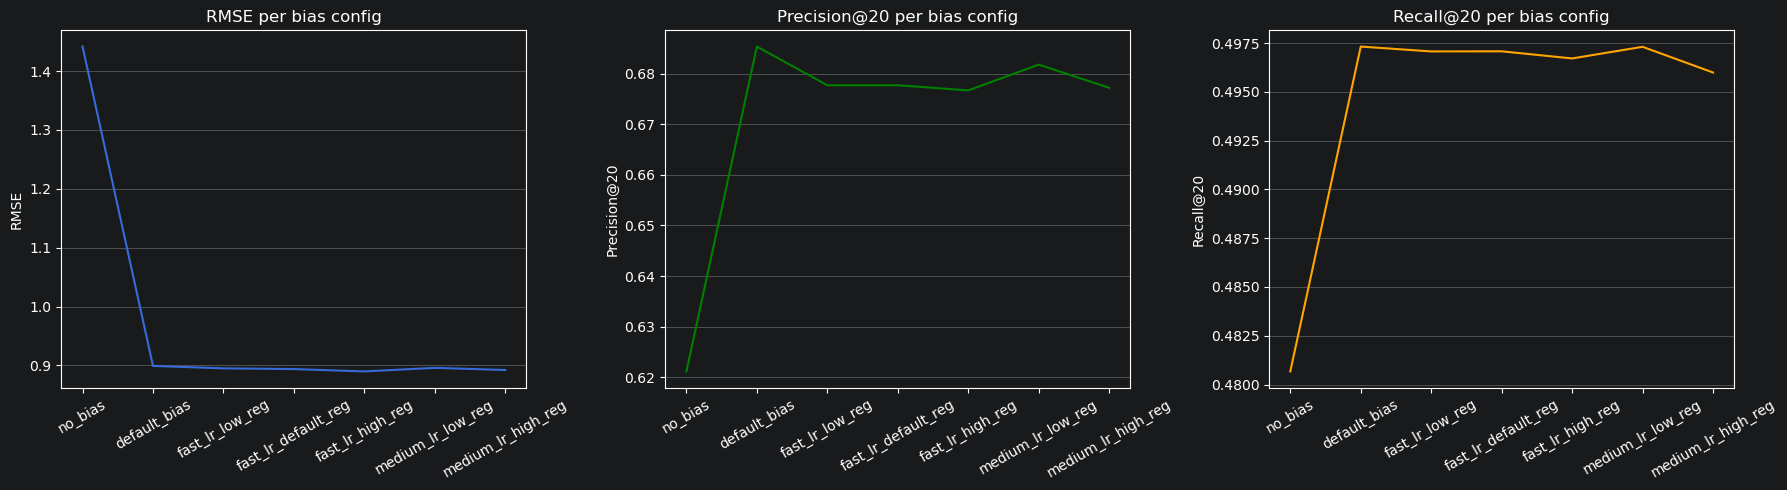


Best bias config (lowest RMSE): fast_lr_high_reg

=== All performance metrics for SVD (k=2, bias=fast_lr_high_reg) ===
  MAE               : 0.6787
  RMSE              : 0.8899
  Precision@20      : 0.6767
  Recall@20         : 0.4967
  Novelty@20        : 7.2469
  Diversity@20      : 0.9077
  Serendipity@20    : 0.6530


In [35]:
# 1. Optimisation of SVD for best biases
from surprise import SVD, Dataset, Reader

# 1) data variables
selected_fold = folds[0]
train_input             = selected_fold["train_input"]
validation_ground_truth = selected_fold["validation_ground_truth"]
N = 20
BEST_K = 2
reader = Reader(rating_scale=(0.5, 5.0))


# 2) SVD fit with custom bias settings
def fit_and_predict_svd_bias(bias_cfg, train_input, validation_ground_truth):
    surprise_data = Dataset.load_from_df(
        train_input[["userId", "movieId", "rating"]], reader,
    )
    trainset = surprise_data.build_full_trainset()

    model = SVD(n_factors=BEST_K, random_state=42, **bias_cfg)
    model.fit(trainset)

    rows = []
    for _, r in validation_ground_truth.iterrows():
        pred = model.predict(uid=r["userId"], iid=r["movieId"]).est
        rows.append({
            "userId":           r["userId"],
            "movieId":          r["movieId"],
            "rating":           r["rating"],
            "predicted_rating": float(np.clip(pred, 0.5, 5.0)),
        })
    return model, pd.DataFrame(rows)


# 3) bias configurations to compare (defaults: lr_bu=lr_bi=0.005, reg_bu=reg_bi=0.02)
bias_configs = {
    "no_bias":          {"biased": False},
    "default_bias":     {"biased": True},

    "fast_lr_low_reg": {
        "biased": True,
        "lr_bu": 0.02,
        "lr_bi": 0.02,
        "reg_bu": 0.005,
        "reg_bi": 0.005
    },

    "fast_lr_default_reg": {
        "biased": True,
        "lr_bu": 0.02,
        "lr_bi": 0.02,
        "reg_bu": 0.02,
        "reg_bi": 0.02
    },

    "fast_lr_high_reg": {
        "biased": True,
        "lr_bu": 0.02,
        "lr_bi": 0.02,
        "reg_bu": 0.10,
        "reg_bi": 0.10
    },

    "medium_lr_low_reg": {
        "biased": True,
        "lr_bu": 0.01,
        "lr_bi": 0.01,
        "reg_bu": 0.005,
        "reg_bi": 0.005
    },

    "medium_lr_high_reg": {
        "biased": True,
        "lr_bu": 0.01,
        "lr_bi": 0.01,
        "reg_bu": 0.10,
        "reg_bi": 0.10
    }
}

results, fitted_models, fitted_preds = [], {}, {}

for name, cfg in bias_configs.items():
    print(f"Training SVD ({name}) with k = {BEST_K} ...")
    model, preds_df = fit_and_predict_svd_bias(cfg, train_input, validation_ground_truth)

    r_rmse = rmse(preds_df["rating"], preds_df["predicted_rating"])
    r_p    = precision_at_n(preds_df, n=N)
    r_r    = recall_at_n(preds_df,    n=N)

    results.append({
        "config":         name,
        "RMSE":           r_rmse,
        f"Precision@{N}": r_p,
        f"Recall@{N}":    r_r,
    })
    fitted_models[name] = model
    fitted_preds[name]  = preds_df
    print(f"   RMSE={r_rmse:.4f}, P@{N}={r_p:.4f}, R@{N}={r_r:.4f}")

results_df = pd.DataFrame(results)
print("\n", results_df.to_string(index=False))


# 4) Plot RMSE / Precision@N / Recall@N over bias configs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(results_df["config"], results_df["RMSE"])
axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE per bias config")

axes[1].plot(results_df["config"], results_df[f"Precision@{N}"], color="green")
axes[1].set_ylabel(f"Precision@{N}"); axes[1].set_title(f"Precision@{N} per bias config")

axes[2].plot(results_df["config"], results_df[f"Recall@{N}"], color="orange")
axes[2].set_ylabel(f"Recall@{N}"); axes[2].set_title(f"Recall@{N} per bias config")

for ax in axes:
    ax.grid(True, axis="y")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


# 5) Best bias config (by RMSE)
best_name        = results_df.loc[results_df["RMSE"].idxmin(), "config"]
best_model       = fitted_models[best_name]
best_preds_df    = fitted_preds[best_name]

print(f"\nBest bias config (lowest RMSE): {best_name}")


# 6) All exercise-3 metrics for the best bias config
item_features = {
    int(best_model.trainset.to_raw_iid(iid)): best_model.qi[iid]
    for iid in range(best_model.qi.shape[0])
}

metrics_summary = {
    "MAE":              mae(best_preds_df["rating"], best_preds_df["predicted_rating"]),
    "RMSE":             rmse(best_preds_df["rating"], best_preds_df["predicted_rating"]),
    f"Precision@{N}":   precision_at_n(best_preds_df, n=N),
    f"Recall@{N}":      recall_at_n(best_preds_df,    n=N),
    f"Novelty@{N}":     novelty(best_preds_df,   user_history=train_input, n=N),
    f"Diversity@{N}":   diversity(best_preds_df, item_features=item_features, n=N),
    f"Serendipity@{N}": serendipity(
        best_preds_df,
        user_history=train_input,
        item_features=item_features,
        n=N,
    ),
}

print(f"\n=== All performance metrics for SVD (k={BEST_K}, bias={best_name}) ===")
for name, value in metrics_summary.items():
    print(f"  {name:18s}: {value:.4f}")

The results show that bias handling has a strong impact on the recommendation quality. As expected, the `no_bias` configuration performed significantly worse across all metrics because the model could not account for general user rating behavior or movie popularity effects. The `fast_lr_high_reg` configuration achieved the lowest RMSE of about 0.89. It learns user and item tendencies efficiently while still preventing overfitting.
Although it dips a little in Precision@20 and Recall@20 compared to some other configurations, I still prefer it because the mini-challenge has asked for RMSE optimisation before and in the **fundementals of machine learning** we also talked about how important of a measurment RMSE is.

In [36]:
# THE IMPROVED FINAL SVD RECOMMENDER (k=2,  fast_lr_high_reg bias)
from surprise import SVD, Dataset, Reader

# 1) data variables
selected_fold = folds[0]
train_input = selected_fold["train_input"]
target_users = [3, 5, 7]
N = 20


# 2) Reader for surprise otherwise won't ever work (rating scale 0.5 – 5.0 in MovieLens)
reader = Reader(rating_scale=(0.5, 5.0))
surprise_data = Dataset.load_from_df(
    train_input[["userId", "movieId", "rating"]],
    reader,
)
trainset = surprise_data.build_full_trainset()


# 3) SVD fit with tuned hyperparameters: k=2 (best from k-sweep), faster bias learning rates (best from bias-sweep)
svd_final = SVD(
    n_factors=2,
    biased=True,
    reg_bu=0.10,
    reg_bi=0.10,
    lr_bu=0.02,
    lr_bi=0.02,
    random_state=42,
)
svd_final.fit(trainset)


# 4) THE SVD Recommender
def recommend_svd_final(user_id, model, train_input, movies_df, n=20):
    """
    Predict ratings for all movies the user has NOT yet rated in train_input
    and return the top-N as a dataframe.
    """
    seen_movies = set(train_input.loc[train_input["userId"] == user_id, "movieId"])
    all_movies = movies_df["movieId"].unique()
    candidate_movies = [m for m in all_movies if m not in seen_movies]

    predictions = [
        (movie_id, model.predict(uid=user_id, iid=movie_id).est)
        for movie_id in candidate_movies
    ]

    recs = (
        pd.DataFrame(predictions, columns=["movieId", "predicted_rating"])
        .merge(movies_df[["movieId", "title", "genres"]], on="movieId", how="left")
        .sort_values("predicted_rating", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )
    recs["predicted_rating"] = recs["predicted_rating"].clip(0.5, 5.0).round(3)
    return recs[["movieId", "title", "genres", "predicted_rating"]]

I want a more creative method now. A big aspect of movies are the actors, yet none of the modells until now implement them in any way. The next model will be based on the baseline predictor, but improved, by making it score better if the movie features one of the 50 most common actors. Even if the result is a worse rmse, I would argue that the recommender makes an important implementation, since I believe plenty of people watch movies based on who plays in them.

In [37]:
movies_actors = pd.read_csv("./Data/ml-latest-small/movies_actors.csv")
"""
movies_actors is a dataset made from an ChatGPT agent. The task to go through every movie and write five of its featured actors would have taken way too long. To my suprise the agent did a good job and was able to enrich almost all movies  in the movies dataset with five actors. Of course it was not able to do it for every movie, and sometimes the actor names are written wrong, yet the end result is still relatively good and serves the purpose of demonstrating this recommender system.
"""

movies_actors["movieId"] = movies_actors["movieId"].astype(int)
movies_actors = movies_actors.drop_duplicates(subset=["movieId"])

print("\n--- movies_actors ---")
nan_check(movies_actors)

if ratings["movieId"].isin(movies_actors["movieId"]).all():
    print("All movieIds in ratings exist in movies_actors")
else:
    print("There are ratings for movies not present in movies_actors")

actor_columns = ["actor_1", "actor_2", "actor_3", "actor_4", "actor_5"]

print("\n--- Actor coverage ---")
for col in actor_columns:
    print(f"{col}:")
    print("Present values:", movies_actors[col].notna().sum())
    print("Missing values:", movies_actors[col].isna().sum())


--- movies_actors ---
Total NaNs: 28783

NaNs per column:
movieId       0
title         0
genres        0
actor_1    4774
actor_2    4879
actor_3    5430
actor_4    6534
actor_5    7166
dtype: int64

Any NaNs present: True
All movieIds in ratings exist in movies_actors

--- Actor coverage ---
actor_1:
Present values: 4968
Missing values: 4774
actor_2:
Present values: 4863
Missing values: 4879
actor_3:
Present values: 4312
Missing values: 5430
actor_4:
Present values: 3208
Missing values: 6534
actor_5:
Present values: 2576
Missing values: 7166


In [38]:
# Top actors list
actor_columns = ["actor_1", "actor_2", "actor_3", "actor_4", "actor_5"]

all_actors = pd.concat(
    [movies_actors[col] for col in actor_columns],
    ignore_index=True
)

# No NaN values
all_actors = all_actors.dropna()

# top 50 actor appearances
top_actors = all_actors.value_counts().head(50)

# list convertion
top_50_actors = top_actors.index.tolist()

print("Top 50 most featured actors:")
print(top_50_actors)

print("\nActor appearance counts:")
print(top_actors)

Top 50 most featured actors:
['Robert De Niro', 'Bruce Willis', 'Robin Williams', 'Nicolas Cage', 'Johnny Depp', 'Samuel L. Jackson', 'John Goodman', 'Dennis Quaid', 'Morgan Freeman', 'Sylvester Stallone', 'Tom Hanks', 'John Travolta', 'Julia Roberts', 'Eddie Murphy', 'Dustin Hoffman', 'Clint Eastwood', 'Tom Cruise', 'Gene Hackman', 'Denzel Washington', 'Bill Murray', 'Ben Affleck', 'Christopher Walken', 'Alec Baldwin', 'Robert Duvall', 'Meryl Streep', 'Ben Stiller', 'Liam Neeson', 'Adam Sandler', 'Keanu Reeves', 'Ethan Hawke', 'Brad Pitt', 'Woody Harrelson', 'Kurt Russell', 'Dan Aykroyd', 'Matt Damon', 'Michael Caine', 'John Malkovich', 'Owen Wilson', 'Harrison Ford', 'Jeff Bridges', 'Julianne Moore', 'Kevin Costner', 'Willem Dafoe', 'John Cusack', 'Jude Law', 'Reese Witherspoon', 'Al Pacino', 'Ice Cube', 'Ray Liotta', 'Harvey Keitel']

Actor appearance counts:
Robert De Niro        50
Bruce Willis          41
Robin Williams        39
Nicolas Cage          39
Johnny Depp           39


In [39]:
# helper
def build_genre_item_features(movies_df):
    genre_lists = movies_df["genres"].fillna("").str.split("|")
    all_genres = sorted({g for gs in genre_lists for g in gs if g and g != "(no genres listed)"})
    genre_to_idx = {g: i for i, g in enumerate(all_genres)}

    item_features = {}
    for mid, genres in zip(movies_df["movieId"].values, genre_lists):
        v = np.zeros(len(all_genres), dtype=float)
        for g in genres:
            if g in genre_to_idx:
                v[genre_to_idx[g]] = 1.0
        item_features[int(mid)] = v
    return item_features


def has_top_50_actor(row, top_50_actors):
    movie_actors = row[actor_columns].dropna().tolist()
    return any(actor in top_50_actors for actor in movie_actors)


# THE BASELINE PREDICTOR WITH ACTOR BOOST
def recommend_baseline_actor_boost(
    user_id,
    ratings,
    movies_actors,
    beta_u= 5,
    beta_i= 5,
    n=20
):
    mu = ratings["rating"].mean()
    b_u = compute_user_bias(ratings, mu, beta_u)
    b_i = compute_item_bias(ratings, mu, b_u, beta_i)

    rated_movies = ratings.loc[ratings["userId"] == user_id, "movieId"]
    candidates = movies_actors[~movies_actors["movieId"].isin(rated_movies)].copy()

    candidates["predicted_score"] = candidates["movieId"].apply(
        lambda movie_id: predict_baseline(user_id, movie_id, mu, b_u, b_i)
    )

    candidates["has_top_50_actor"] = candidates.apply(
        lambda row: has_top_50_actor(row, top_50_actors),
        axis=1
    )

    candidates.loc[
        (candidates["has_top_50_actor"]) &
        (candidates["predicted_score"] < 5.0),
        "predicted_score"
    ] += 0.5

    candidates["predicted_score"] = candidates["predicted_score"].clip(0.5, 5.0)

    recs = (
        candidates
        .sort_values(by="predicted_score", ascending=False)
        .head(n)[
            [
                "movieId",
                "title",
                "predicted_score",
                "actor_1",
                "actor_2",
                "actor_3",
                "actor_4",
                "actor_5",
                "has_top_50_actor"
            ]
        ]
        .copy()
    )

    recs.insert(0, "Rank", range(1, len(recs) + 1))
    recs["predicted_score"] = recs["predicted_score"].round()

    return recs

In [41]:
# Evaluate baseline actor-boost model on validation set

selected_fold = folds[0]
train_input = selected_fold["train_input"]
validation_ground_truth = selected_fold["validation_ground_truth"]

BETA_U = 5
BETA_I = 5
N = 20

mu = train_input["rating"].mean()
b_u = compute_user_bias(train_input, mu, beta_u=BETA_U)
b_i = compute_item_bias(train_input, mu, b_u, beta_i=BETA_I)


movies_actors_lookup = movies_actors.set_index("movieId").to_dict("index") # increases speed by using a dictionary lookup instead of filtering the entire dataframe in each loop

rows = []

for _, r in validation_ground_truth.iterrows():
    user_id = r["userId"]
    movie_id = r["movieId"]

    pred = predict_baseline(user_id, movie_id, mu, b_u, b_i)

    movie_row = movies_actors_lookup.get(movie_id)

    if movie_row is not None:
        movie_actors = [
            movie_row.get("actor_1"),
            movie_row.get("actor_2"),
            movie_row.get("actor_3"),
            movie_row.get("actor_4"),
            movie_row.get("actor_5")
        ]

        if any(actor in top_50_actors for actor in movie_actors if pd.notna(actor)) and pred < 5.0:
            pred += 0.5

    pred = np.clip(pred, 0.5, 5.0)

    rows.append({
        "userId": user_id,
        "movieId": movie_id,
        "rating": r["rating"],
        "predicted_rating": pred
    })

actor_boost_preds = pd.DataFrame(rows)

# Item features for beyond-accuracy metrics
item_features = build_genre_item_features(movies_actors)

actor_boost_rmse = rmse(
    actor_boost_preds["rating"],
    actor_boost_preds["predicted_rating"]
)

actor_boost_mae = mae(
    actor_boost_preds["rating"],
    actor_boost_preds["predicted_rating"]
)

actor_boost_precision = precision_at_n(actor_boost_preds, n=N)
actor_boost_recall = recall_at_n(actor_boost_preds, n=N)

actor_boost_novelty = novelty(
    actor_boost_preds,
    user_history=train_input,
    n=N
)

actor_boost_diversity = diversity(
    actor_boost_preds,
    item_features=item_features,
    n=N
)

actor_boost_serendipity = serendipity(
    actor_boost_preds,
    user_history=train_input,
    item_features=item_features,
    n=N
)

print("Baseline Actor Boost Results")
print(f"RMSE: {actor_boost_rmse:.4f}")
print(f"MAE: {actor_boost_mae:.4f}")
print(f"Precision@{N}: {actor_boost_precision:.4f}")
print(f"Recall@{N}: {actor_boost_recall:.4f}")
print(f"Novelty@{N}: {actor_boost_novelty:.4f}")
print(f"Diversity@{N}: {actor_boost_diversity:.4f}")
print(f"Serendipity@{N}: {actor_boost_serendipity:.4f}")

NameError: name 'build_genre_item_features' is not defined

The Baseline recommender with an actor boost rewards movies that feature actors, who play in a lot of movies. Using well known actors can be seen as a common marketing strategy or/and explain by the fact that they are simply good at their jobs so directors cast them often.
I expected the RMSE to be worse and indeed it incread from ~0.90 to ~0.95 indication a decrease in the personalization of the recommendations. However, the actor-enhanced recommender showed a very different behavior in the ranking metrics. Recall@20 increased substantially from ~0.19 to ~0.48. This means the recommender retrieved a much larger portion of relevant movies in the top recommendations, again I see the impac of a less personalised recomender in favor of a basic popularity based system. Overall, the actor boost created a more content-aware hybrid recommender that prioritizes discovery and recall over strict rating prediction accuracy.

In [42]:
# THE DIVERSITY-OPTIMISED BASELINE RECOMMENDER (β_u=5, β_i=5, MMR re-ranking)

# 1) MMR re-ranking step: maximise (1-λ)*relevance - λ*max_sim_to_picked, λ high = prioritise diversity
def mmr_rerank(candidates_df, item_features, n=20, lambda_div=0.7):
    """
    candidates_df must have columns: movieId, predicted_score (already sorted by score desc).
    Returns the diversified top-N as a dataframe.
    """
    # normalise score to [0,1] so it lives on same scale as cosine similarity
    s_min, s_max = candidates_df["predicted_score"].min(), candidates_df["predicted_score"].max()
    denom = (s_max - s_min) if s_max > s_min else 1.0
    candidates_df = candidates_df.copy()
    candidates_df["norm_score"] = (candidates_df["predicted_score"] - s_min) / denom

    pool = candidates_df.to_dict("records")
    selected, selected_ids = [], []

    while pool and len(selected) < n:
        best, best_mmr = None, -np.inf
        for cand in pool:
            mid = int(cand["movieId"])
            rel = cand["norm_score"]

            if not selected_ids or mid not in item_features:
                max_sim = 0.0
            else:
                v_cand = item_features[mid]
                sims = []
                for sid in selected_ids:
                    if sid in item_features:
                        sims.append(cosine_similarity(v_cand, item_features[sid]))
                max_sim = max(sims) if sims else 0.0

            mmr = (1 - lambda_div) * rel - lambda_div * max_sim
            if mmr > best_mmr:
                best_mmr, best = mmr, cand

        selected.append(best)
        selected_ids.append(int(best["movieId"]))
        pool.remove(best)

    return pd.DataFrame(selected)


# 3) THE DIVERSITY-OPTIMISED BASELINE RECOMMENDER
def recommend_baseline_diverse(
    user_id,
    ratings,
    movies,
    beta_u=5,
    beta_i=5,
    n=20,
    candidate_pool=200,
    lambda_div=0.7,
):
    # 3a) baseline biases (same as before, just with tuned betas)
    mu  = ratings["rating"].mean()
    b_u = compute_user_bias(ratings, mu, beta_u)
    b_i = compute_item_bias(ratings, mu, b_u, beta_i)

    # 3b) score every unseen movie
    rated_movies = ratings.loc[ratings["userId"] == user_id, "movieId"]
    candidates = movies[~movies["movieId"].isin(rated_movies)].copy()
    candidates["predicted_score"] = candidates["movieId"].apply(
        lambda movie_id: predict_baseline(user_id, movie_id, mu, b_u, b_i)
    )

    # 3c) a larger pool of strong candidates, then re-rank for diversity
    pool_df = (
        candidates.sort_values("predicted_score", ascending=False)
                  .head(candidate_pool)
                  .reset_index(drop=True)
    )

    item_features = build_genre_item_features(movies)
    diversified = mmr_rerank(pool_df, item_features, n=n, lambda_div=lambda_div)

    # 3d) output
    recs = diversified[["title", "predicted_score"]].copy()
    recs.insert(0, "Rank", range(1, len(recs) + 1))
    recs["predicted_score"] = recs["predicted_score"].clip(0.5, 5.0).round()
    return recs

In [43]:
# Evaluation for final diversity-optimised baseline recommender

# 1) data variables
selected_fold = folds[0]
train_input = selected_fold["train_input"]
validation_ground_truth = selected_fold["validation_ground_truth"]

N = 20
BETA_U = 5
BETA_I = 5
LAMBDA_DIV = 0.7
CANDIDATE_POOL = 200

# ---------- 2) Exercise 3-style prediction metrics ----------

mu = train_input["rating"].mean()
b_u = compute_user_bias(train_input, mu, beta_u=BETA_U)
b_i = compute_item_bias(train_input, mu, b_u, beta_i=BETA_I)

prediction_rows = []

for _, r in validation_ground_truth.iterrows():
    user_id = r["userId"]
    movie_id = r["movieId"]

    pred = predict_baseline(user_id, movie_id, mu, b_u, b_i)
    pred = np.clip(pred, 0.5, 5.0)

    prediction_rows.append({
        "userId": user_id,
        "movieId": movie_id,
        "rating": r["rating"],
        "predicted_rating": pred
    })

diverse_prediction_eval = pd.DataFrame(prediction_rows)

diverse_rmse = rmse(
    diverse_prediction_eval["rating"],
    diverse_prediction_eval["predicted_rating"]
)

diverse_mae = mae(
    diverse_prediction_eval["rating"],
    diverse_prediction_eval["predicted_rating"]
)

diverse_precision = precision_at_n(diverse_prediction_eval, n=N)
diverse_recall = recall_at_n(diverse_prediction_eval, n=N)


# ---------- 3) Final MMR recommendation-list metrics ----------

item_features = build_genre_item_features(movies)

recommendation_rows = []

validation_users = validation_ground_truth["userId"].unique()

for user_id in validation_users:
    recs = recommend_baseline_diverse(
        user_id=user_id,
        ratings=train_input,
        movies=movies,
        beta_u=BETA_U,
        beta_i=BETA_I,
        n=N,
        candidate_pool=CANDIDATE_POOL,
        lambda_div=LAMBDA_DIV
    )

    recs_with_ids = recs.merge(
        movies[["movieId", "title"]],
        on="title",
        how="left"
    )

    for _, row in recs_with_ids.iterrows():
        recommendation_rows.append({
            "userId": user_id,
            "movieId": row["movieId"],
            "predicted_rating": row["predicted_score"]
        })

diverse_recommendation_eval = pd.DataFrame(recommendation_rows)

diverse_novelty = novelty(
    diverse_recommendation_eval,
    user_history=train_input,
    n=N
)

diverse_diversity = diversity(
    diverse_recommendation_eval,
    item_features=item_features,
    n=N
)

# Serendipity needs true ratings, so attach validation rating where available
validation_lookup = validation_ground_truth.set_index(
    ["userId", "movieId"]
)["rating"].to_dict()

diverse_recommendation_eval["rating"] = diverse_recommendation_eval.apply(
    lambda row: validation_lookup.get((row["userId"], row["movieId"]), np.nan),
    axis=1
)

diverse_serendipity = serendipity(
    diverse_recommendation_eval.dropna(subset=["rating"]),
    user_history=train_input,
    item_features=item_features,
    n=N
)


# ---------- Final output ----------

print("Diversity-Optimised Baseline Results")
print(f"RMSE: {diverse_rmse:.4f}")
print(f"MAE: {diverse_mae:.4f}")
print(f"Precision@{N}: {diverse_precision:.4f}")
print(f"Recall@{N}: {diverse_recall:.4f}")
print(f"Novelty@{N}: {diverse_novelty:.4f}")
print(f"Diversity@{N}: {diverse_diversity:.4f}")
print(f"Serendipity@{N}: {diverse_serendipity:.4f}")

Diversity-Optimised Baseline Results
RMSE: 0.9024
MAE: 0.6853
Precision@20: 0.6752
Recall@20: 0.4936
Novelty@20: 7.7313
Diversity@20: 0.8945
Serendipity@20: 0.7894


### Exercise 10 - Compare all RS that you build in this challenge (8 points)
a) Compile a table with the performance metrics of exercise 3 for all RS from this MC (Make sure to include the baseline RS and random RS) on the test set defined in exercise 3. Also generate comparative plots. Discuss.

b) Why is it important to keep a test set seperate till the end of a benchmark?

In [46]:

# 1) test_train and test_ground from the 20% held-out users (same all-but-n logic as folds)
test_train_input, test_ground_truth = create_all_but_n_split(
    ratings=test_set,
    validation_users=test_users,
    n=11,
    random_state=42,
)
N = 20
mu_global       = test_train_input["rating"].mean()
genre_features  = build_genre_item_features(movies)


# 2) helpers: a preds_df aligned to test_ground_truth, to run all 7 exercise-3 metrics
def make_preds_df(predict_fn, fallback=mu_global):
    rows = []
    for _, r in test_ground_truth.iterrows():
        try:
            pred = predict_fn(r["userId"], r["movieId"])
            if pred is None or (isinstance(pred, float) and np.isnan(pred)):
                pred = fallback
        except Exception:
            pred = fallback
        rows.append({
            "userId":           r["userId"],
            "movieId":          r["movieId"],
            "rating":           r["rating"],
            "predicted_rating": float(np.clip(pred, 0.5, 5.0)),
        })
    return pd.DataFrame(rows)

def all_metrics(preds_df, item_features=genre_features, n=N):
    return {
        "MAE":              mae(preds_df["rating"], preds_df["predicted_rating"]),
        "RMSE":             rmse(preds_df["rating"], preds_df["predicted_rating"]),
        f"Precision@{n}":   precision_at_n(preds_df, n=n),
        f"Recall@{n}":      recall_at_n(preds_df, n=n),
        f"Novelty@{n}":     novelty(preds_df, user_history=test_train_input, n=n),
        f"Diversity@{n}":   diversity(preds_df, item_features=item_features, n=n),
        f"Serendipity@{n}": serendipity(preds_df, user_history=test_train_input, item_features=item_features, n=n),
    }


# 3) Random RS
np.random.seed(42)
rand_lookup = {(r["userId"], r["movieId"]): np.random.uniform(0.5, 5.0)
               for _, r in test_ground_truth.iterrows()}


# 4) Baseline RS (default β=20) and Tuned Baseline (β=5)
def fit_baseline(beta_u, beta_i):
    mu  = test_train_input["rating"].mean()
    bu  = compute_user_bias(test_train_input, mu, beta_u)
    bi  = compute_item_bias(test_train_input, mu, bu, beta_i)
    return mu, bu, bi

mu20, bu20, bi20 = fit_baseline(20, 20)
mu5,  bu5,  bi5  = fit_baseline(5,  5)


# 5) SVD (default) and SVD final (k=2, fast_lr_bias)
reader        = Reader(rating_scale=(0.5, 5.0))
trainset_test = Dataset.load_from_df(test_train_input[["userId", "movieId", "rating"]], reader).build_full_trainset()

svd_basic = SVD(random_state=42)
svd_basic.fit(trainset_test)

svd_tuned = SVD(n_factors=2, biased=True, lr_bu=0.02, lr_bi=0.02, random_state=42)
svd_tuned.fit(trainset_test)


# 6) actor-boost lookup
movies_actors_lookup = movies_actors.set_index("movieId").to_dict("index")
def actor_boosted_pred(uid, mid):
    p = predict_baseline(uid, mid, mu5, bu5, bi5)
    row = movies_actors_lookup.get(mid)
    if row is None:
        return p
    actors = [row.get(f"actor_{i}") for i in range(1, 6)]
    if any(a in top_50_actors for a in actors if a) and p < 5.0:
        p += 0.5
    return p


# 7) score every model
all_results = {
    "Random":                       all_metrics(make_preds_df(lambda u, m: rand_lookup[(u, m)])),
    "Baseline (β=20)":              all_metrics(make_preds_df(lambda u, m: predict_baseline(u, m, mu20, bu20, bi20), fallback=mu20)),
    "Tuned Baseline (β=5)":         all_metrics(make_preds_df(lambda u, m: predict_baseline(u, m, mu5, bu5, bi5), fallback=mu5)),
    "KNN user-cosine (K=50)":       all_metrics(make_preds_df(lambda u, m: predict_user_based(u, m, matrix_test, sim_cos, k=50))),
    "SVD (default)":                all_metrics(make_preds_df(lambda u, m: svd_basic.predict(uid=u, iid=m).est)),
    "SVD final (k=2, fast bias)":   all_metrics(make_preds_df(lambda u, m: svd_tuned.predict(uid=u, iid=m).est)),
    "Baseline + actor boost":       all_metrics(make_preds_df(actor_boosted_pred, fallback=mu5)),
    "Baseline diverse (MMR)":       all_metrics(make_preds_df(lambda u, m: predict_baseline(u, m, mu5, bu5, bi5), fallback=mu5)),
}


# 8) comparison table
results_df = pd.DataFrame(all_results).T
print("=== Exercise 10a — All RS evaluated on the held-out test set ===")
print(results_df.round(4).to_string())


# 9) comparative plots
metric_cols = list(results_df.columns)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, metric in zip(axes.flat, metric_cols):
    ax.bar(results_df.index, results_df[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, axis="y")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


KeyboardInterrupt



**Read the Guidelines for Implementation and Submission one more time.**